# วัตถุประสงค์ข้อ 2 พยากรณ์ตลาดและอัตราการเข้าพัก

Notebook หลักสำหรับ Market & Occupancy Forecasting เรียงงานไว้ในไฟล์เดียวเหมือน Notebook 04
ใช้ข้อมูลจำลองของโปรเจกต์ ยังไม่ใช่ข้อมูลผลประกอบการจริง

- ส่วนที่ 1: ตรวจข้อมูลและ EDA จำนวน 12 ขั้นตอน
- ส่วนที่ 2: เตรียมข้อมูลสำหรับ SARIMA, SARIMAX และ Random Forest จำนวน 12 ขั้นตอน
- ส่วนที่ 3: ฝึก เปรียบเทียบ และประเมิน 5 วิธี จำนวน 12 ขั้นตอน
- ส่วนที่ 4: จูนด้วย TrainCV และเทียบ Validation ก่อน/หลัง จำนวน 10 ขั้นตอน

อ่านและ Run All จากต้นจนจบ เปิดได้จาก root หรือโฟลเดอร์ notebooks
โค้ดที่ใช้ซ้ำอยู่ใน src/kaverentai/features/market_occupancy_features.py
ผล EDA อยู่ใน reports/market_occupancy/eda/ ข้อมูลสำหรับฝึกอยู่ใน data/modeling/market_occupancy/
และสรุปการเตรียมข้อมูลอยู่ใน reports/market_occupancy/features/

ส่วนที่ 3 ฝึกโมเดลแล้วเปรียบเทียบ Validation/Test พร้อม MAE/RMSE และกราฟ
ช่วง 1, 4, 12 สัปดาห์เป็นกรอบทดลองของโครงงาน ไม่ใช่ช่วงที่งานวิจัยกำหนดว่าเหมาะที่สุด


## วิธีอ่านโค้ดสำหรับวัตถุประสงค์ข้อ 2

เริ่มจาก Notebook นี้ตามลำดับ 4 ส่วน: ตรวจข้อมูล → สร้าง features → ฝึก/ประเมิน → จูน
แต่ละ cell พยายามแยกงานให้เห็นว่าใช้ตารางไหน กรองอะไร และได้ผลอะไร

- target คือค่าที่จะพยากรณ์; horizon คือจำนวนสัปดาห์ล่วงหน้า
- origin คือวันเริ่มพยากรณ์; cutoff คือวันสุดท้ายที่อนุญาตให้ใช้ fit
- `mask`/เงื่อนไข เช่น `data["split"] == "Train"` ใช้เลือกแถวด้วย True/False
- `groupby("project_id")` คำนวณแยกโครงการ; `merge` จับคู่ตารางด้วยคอลัมน์ชื่อเดียวกัน
- `Pipeline` รวมการเตรียม features กับโมเดล เพื่อ fit บนข้อมูลฝึกชุดเดียวกัน
- `experiment = ForecastExperiment()` สร้างตัวช่วยเก็บข้อมูลการทดลอง; `self` ในไฟล์โมเดลหมายถึง experiment นี้
- `cache` คือผลที่บันทึกไว้แล้ว เพื่อไม่ต้องฝึกซ้ำเมื่อข้อมูลและพารามิเตอร์ตรงกัน

อ่านรายละเอียด features ใน `src/kaverentai/features/market_occupancy_features.py`
อ่านขั้นตอนฝึกใน `src/kaverentai/models/train_market_occupancy.py`
แล้วตามไปอ่าน `fit_rf`, `fit_time_series`, `forecast_time_series` ในไฟล์โมเดล
ขั้นตอนจูนอยู่ใน `src/kaverentai/models/tune_market_occupancy.py`

# ส่วนที่ 1 ตรวจข้อมูลและ EDA

ใช้ทั้งชุดเพื่อตรวจคุณภาพและความสอดคล้อง แต่แนวโน้ม ฤดูกาล และความสัมพันธ์ใช้เฉพาะ Train ถึงสิ้นปี 2025
ใช้ weekly_market เป็นตารางหลัก projects เพิ่มข้อมูลโครงการ และ units/leases ใช้ตรวจสอบจำนวนห้อง


## 1. Import และตั้งค่าตำแหน่งไฟล์

ใช้ pandas จัดตาราง matplotlib/seaborn สร้างกราฟ และตัวโหลดข้อมูลเดิมของโปรเจกต์
ตั้งฟอนต์ Tahoma เมื่อมีบนเครื่อง เพื่อให้ชื่อโครงการภาษาไทยแสดงได้

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import font_manager
from IPython.display import display, Markdown

In [2]:
# หาโฟลเดอร์หลัก รองรับการเปิดจาก root และ notebooks
PROJECT_ROOT = Path.cwd()
PROJECT_ROOT = PROJECT_ROOT.resolve()
while not (PROJECT_ROOT / "data" / "processed").is_dir():
    if PROJECT_ROOT == PROJECT_ROOT.parent:
        raise FileNotFoundError("เปิด Notebook ภายในโฟลเดอร์โปรเจกต์นี้")
    PROJECT_ROOT = PROJECT_ROOT.parent

sys.path.insert(0, str(PROJECT_ROOT / "src"))
from kaverentai.data.load_data import load_all_data
from kaverentai.data.split_data import chronological_split

REPORT_DIR = PROJECT_ROOT / "reports" / "market_occupancy" / "eda"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

In [3]:
sns.set_theme(style="whitegrid")
thai_font = Path("C:/Windows/Fonts/tahoma.ttf")
if thai_font.is_file():
    font_manager.fontManager.addfont(str(thai_font))
    plt.rcParams["font.family"] = font_manager.FontProperties(fname=str(thai_font)).get_name()
plt.rcParams["axes.unicode_minus"] = False

TARGET_COLUMNS = ["occupancy", "n_searchers", "n_listings_open", "median_asking_rent"]
print("ข้อมูล:", PROJECT_ROOT / "data" / "processed")
print("ผลลัพธ์:", REPORT_DIR)

ข้อมูล: D:\final project_\data\processed
ผลลัพธ์: D:\final project_\reports\market_occupancy\eda


## 2. โหลดและดูตัวอย่างข้อมูล

`weekly_market` เป็นตารางหลัก หนึ่งแถวต่อโครงการต่อสัปดาห์
`projects` บอกจำนวนห้องทั้งหมด `units` ใช้นับห้องเพื่อตรวจจำนวน และ `leases` ใช้เทียบสัญญา
ไม่เชื่อมสัญญาทุกแถวเข้ากับตลาดโดยตรง เพราะจะทำให้หนึ่งสัปดาห์มีแถวซ้ำ

In [4]:
# โหลดข้อมูลทั้งชุดเพื่อเช็กความหมายและความครบถ้วนของตาราง
data = load_all_data(cleaned=True, data_dir=PROJECT_ROOT / "data" / "processed")
weekly = data["weekly_market"].copy()
projects = data["projects"].copy()
units = data["units"].copy()
leases = data["leases"].copy()

# สรุปจำนวนแถว/คอลัมน์ทีละตาราง
inventory_rows = []
for name, frame in data.items():
    inventory_rows.append({"table": name, "rows": len(frame), "columns": len(frame.columns)})
inventory = pd.DataFrame(inventory_rows)
display(inventory)
display(weekly.head())
display(projects.head())

,table,rows,columns
0,projects,19,7
1,units,15367,8
2,listings,31544,24
3,leases,50965,10
4,weekly_market,2288,9


,week,date,project_id,season,n_searchers,n_listings_open,n_units_leased,occupancy,median_asking_rent
0,0,2023-01-03,0,normal,21,101,488,0.828523,10010.0
1,0,2023-01-03,1,normal,39,166,907,0.845294,10480.0
2,0,2023-01-03,2,normal,36,180,893,0.832246,10965.0
3,0,2023-01-03,3,normal,55,285,1485,0.838983,11110.0
4,0,2023-01-03,4,normal,40,155,928,0.856879,11260.0


,project_id,project_name,university,distance_to_campus_m,total_units,year_completed,facility_count
0,0,Kave Condo,ม.กรุงเทพ,100,589,2018,20
1,1,Kave Town Space,ม.กรุงเทพ,200,1073,2020,30
2,2,Kave Town Shift,ม.กรุงเทพ,200,1073,2020,30
3,3,Kave Town Island,ม.กรุงเทพ,300,1770,2023,45
4,4,Kave Town Colony,ม.กรุงเทพ,300,1083,2023,40


### ความหมายของตัวแปรที่ใช้

อ้างอิงคำอธิบายใน Notebook 01 และตรวจสูตรจริงในขั้นตอนที่ 4 อีกครั้ง

In [5]:
dictionary = pd.DataFrame([
    ["date / week", "วันที่สังเกตและลำดับสัปดาห์"],
    ["project_id", "รหัสโครงการ"],
    ["season", "ฤดูกาล normal / peak / shoulder / off"],
    ["n_searchers", "จำนวนผู้ค้นหาในสัปดาห์นั้น"],
    ["n_listings_open", "จำนวนประกาศเปิดในสัปดาห์นั้น"],
    ["n_units_leased", "จำนวนห้องที่มีผู้เช่าอยู่ ณ สัปดาห์นั้น ไม่ใช่สัญญาใหม่"],
    ["occupancy", "อัตราการเข้าพัก สัดส่วน 0–1"],
    ["median_asking_rent", "มัธยฐานราคาเสนอเช่ารายเดือน บาท; ไม่ใช่ราคาตามสัญญา"],
    ["total_units", "จำนวนห้องทั้งหมดในโครงการ"],
], columns=["column", "meaning"])
display(dictionary)

,column,meaning
0,date / week,วันที่สังเกตและลำดับสัปดาห์
1,project_id,รหัสโครงการ
2,season,ฤดูกาล normal / peak / shoulder / off
3,n_searchers,จำนวนผู้ค้นหาในสัปดาห์นั้น
4,n_listings_open,จำนวนประกาศเปิดในสัปดาห์นั้น
5,n_units_leased,จำนวนห้องที่มีผู้เช่าอยู่ ณ สัปดาห์นั้น ไม่ใช่...
6,occupancy,อัตราการเข้าพัก สัดส่วน 0–1
7,median_asking_rent,มัธยฐานราคาเสนอเช่ารายเดือน บาท; ไม่ใช่ราคาตาม...
8,total_units,จำนวนห้องทั้งหมดในโครงการ


## 3. ตรวจ schema ชนิดข้อมูล ค่าว่าง ค่าซ้ำ และช่วงค่า

แปลงวันที่โดยไม่แก้ CSV ตรวจทั้งชุดเพื่อหาปัญหาเชิงโครงสร้าง
ราคาเป็นค่าว่างได้เมื่อไม่มีประกาศเปิด: ห้ามเติมศูนย์หรือราคาจากอนาคต

In [6]:
required_columns = ["project_id", "date", "week", "season", "n_units_leased"] + TARGET_COLUMNS
missing_columns = sorted(set(required_columns) - set(weekly.columns))
if missing_columns:
    raise ValueError(f"weekly_market ขาดคอลัมน์: {missing_columns}")

weekly["date"] = pd.to_datetime(weekly["date"], errors="coerce")
weekly = weekly.sort_values(["project_id", "date"])
weekly = weekly.reset_index(drop=True)
weekly.info()

missing_table = weekly.isna()
missing_table = missing_table.sum()
missing_table = missing_table.rename("missing_count")
missing_table = missing_table.to_frame()
missing_table["missing_percent"] = missing_table["missing_count"] / len(weekly) * 100
display(missing_table)

count_columns = ["week", "n_searchers", "n_listings_open", "n_units_leased"]
checks = [
    {"check": "วันที่แปลงไม่ได้", "failures": weekly["date"].isna().sum()},
    {"check": "project_id/date ซ้ำ", "failures": weekly.duplicated(["project_id", "date"]).sum()},
    {"check": "project_id/week ซ้ำ", "failures": weekly.duplicated(["project_id", "week"]).sum()},
    {"check": "project_id ไม่พบใน projects", "failures": (~weekly["project_id"].isin(projects["project_id"])).sum()},
    {"check": "occupancy ว่างหรือนอกช่วง 0–1", "failures": (~weekly["occupancy"].between(0, 1)).sum()},
    {"check": "ฤดูกาลไม่อยู่ในรายการ", "failures": (~weekly["season"].isin(["normal", "peak", "shoulder", "off"])).sum()},
    {"check": "ราคาเป็นค่าว่างทั้งที่มีประกาศ", "failures": (weekly["median_asking_rent"].isna() & (weekly["n_listings_open"] > 0)).sum()},
    {"check": "ราคาที่มีค่าไม่เป็นบวกหรือไม่ finite", "failures": (weekly["median_asking_rent"].notna() & (~np.isfinite(weekly["median_asking_rent"]) | (weekly["median_asking_rent"] <= 0))).sum()},
]
for column in count_columns:
    invalid = weekly[column].isna() | ~np.isfinite(weekly[column]) | (weekly[column] < 0) | (weekly[column].mod(1) != 0)
    checks.append({"check": f"{column} ไม่ใช่จำนวนเต็มไม่ติดลบ", "failures": invalid.sum()})

quality_checks = pd.DataFrame(checks)
display(quality_checks)
display(weekly.loc[weekly["median_asking_rent"].isna()])

# ไม่ลบหรือเติมข้อมูลอัตโนมัติ หากกฎหลักไม่ผ่านให้ตรวจสาเหตุก่อน
if quality_checks["failures"].sum() > 0:
    raise ValueError("พบข้อมูลผิดกฎหลัก ดู quality_checks ก่อนทำ EDA ต่อ")

<class 'pandas.DataFrame'>
RangeIndex: 2288 entries, 0 to 2287
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   week                2288 non-null   int64         
 1   date                2288 non-null   datetime64[us]
 2   project_id          2288 non-null   int64         
 3   season              2288 non-null   str           
 4   n_searchers         2288 non-null   int64         
 5   n_listings_open     2288 non-null   int64         
 6   n_units_leased      2288 non-null   int64         
 7   occupancy           2288 non-null   float64       
 8   median_asking_rent  2285 non-null   float64       
dtypes: datetime64[us](1), float64(2), int64(5), str(1)
memory usage: 172.1 KB


,missing_count,missing_percent
week,0,0.000000
date,0,0.000000
project_id,0,0.000000
season,0,0.000000
n_searchers,0,0.000000
n_listings_open,0,0.000000
n_units_leased,0,0.000000
occupancy,0,0.000000
median_asking_rent,3,0.131119


,check,failures
0,วันที่แปลงไม่ได้,0
1,project_id/date ซ้ำ,0
2,project_id/week ซ้ำ,0
3,project_id ไม่พบใน projects,0
4,occupancy ว่างหรือนอกช่วง 0–1,0
5,ฤดูกาลไม่อยู่ในรายการ,0
6,ราคาเป็นค่าว่างทั้งที่มีประกาศ,0
7,ราคาที่มีค่าไม่เป็นบวกหรือไม่ finite,0
8,week ไม่ใช่จำนวนเต็มไม่ติดลบ,0
9,n_searchers ไม่ใช่จำนวนเต็มไม่ติดลบ,0


,week,date,project_id,season,n_searchers,n_listings_open,n_units_leased,occupancy,median_asking_rent
677,131,2025-07-08,3,peak,207,0,1770,1.0,NaN
1308,138,2025-08-26,7,normal,90,0,1423,1.0,NaN
1309,139,2025-09-02,7,normal,56,0,1423,1.0,NaN


## 4. เชื่อมข้อมูลโครงการและตรวจนิยาม occupancy

เชื่อมแบบ many-to-one เพื่อป้องกันจำนวนแถวเพิ่มจาก project_id ซ้ำ
ตรวจว่า occupancy = n_units_leased / total_units และห้องที่มีผู้เช่า + ประกาศเปิด = ห้องทั้งหมดหรือไม่
สูตรที่ตรงกันยืนยันความสอดคล้องของข้อมูลชุดนี้ แต่ไม่ได้ยืนยันนิยามในระบบธุรกิจจริง

In [7]:
market_data = weekly.merge(projects, on="project_id", how="left", validate="many_to_one")
unit_counts = units.groupby("project_id")["unit_id"].nunique()
unit_counts = unit_counts.rename("units_in_file")
capacity_check = projects.merge(unit_counts, on="project_id", how="left")
capacity_check["difference"] = capacity_check["units_in_file"] - capacity_check["total_units"]
display(capacity_check[["project_id", "project_name", "total_units", "units_in_file", "difference"]])

market_data["calculated_occupancy"] = market_data["n_units_leased"] / market_data["total_units"]
market_data["occupancy_error"] = (market_data["occupancy"] - market_data["calculated_occupancy"]).abs()
identity_checks = pd.DataFrame([
    {"check": "occupancy ไม่ตรงกับ n_units_leased / total_units", "failures": (market_data["occupancy_error"] > 1e-9).sum()},
    {"check": "n_units_leased + n_listings_open ไม่เท่ากับ total_units", "failures": (market_data["n_units_leased"] + market_data["n_listings_open"] != market_data["total_units"]).sum()},
    {"check": "จำนวนห้องใน units ไม่ตรง total_units", "failures": (capacity_check["difference"] != 0).sum()},
])
display(identity_checks)
print("ความคลาดเคลื่อนสูงสุดของสูตร occupancy:", market_data["occupancy_error"].max())

,project_id,project_name,total_units,units_in_file,difference
0,0,Kave Condo,589,589,0
1,1,Kave Town Space,1073,1073,0
2,2,Kave Town Shift,1073,1073,0
3,3,Kave Town Island,1770,1770,0
4,4,Kave Town Colony,1083,1083,0
5,5,Kave TU,1016,1016,0
6,6,Kave Ava,1278,1278,0
7,7,Kave Wonderland,1423,1423,0
8,8,Kave Carnival,850,850,0
9,9,Kave Embryo,514,514,0


,check,failures
0,occupancy ไม่ตรงกับ n_units_leased / total_units,0
1,n_units_leased + n_listings_open ไม่เท่ากับ to...,0
2,จำนวนห้องใน units ไม่ตรง total_units,0


ความคลาดเคลื่อนสูงสุดของสูตร occupancy: 1.1102230246251565e-16


### เทียบห้องที่มีผู้เช่ากับสัญญาที่มองเห็นใน leases

ใช้ unique unit_id เพื่อไม่ให้นับสัญญาซ้อนเป็นหลายห้อง
แสดงสองสมมติฐานสำหรับ week_end: รวมและไม่รวมสัปดาห์สิ้นสุด
ความต่างอาจเกิดจากสัญญาก่อนช่วงข้อมูลหรือวิธีสร้างข้อมูลจำลอง ต้องตรวจที่มาของข้อมูลเพิ่มเติม
ไม่สร้าง occupancy ทดแทนจาก leases หากยังนับห้องที่มีผู้เช่าไม่ตรงกัน

In [8]:
lease_comparison_rows = []
for project_id, project_weeks in market_data.groupby("project_id"):
    project_leases = leases.loc[(leases["project_id"] == project_id)]
    for row in project_weeks.itertuples():
        started = (project_leases["week_start"] <= row.week)
        active_exclusive = started & (project_leases["week_end"] > row.week)
        active_inclusive = started & (project_leases["week_end"] >= row.week)
        lease_comparison_rows.append({
            "project_id": project_id,
            "date": row.date,
            "reported_units_leased": row.n_units_leased,
            "active_units_end_exclusive": project_leases.loc[active_exclusive, "unit_id"].nunique(),
            "active_units_end_inclusive": project_leases.loc[active_inclusive, "unit_id"].nunique(),
        })

lease_comparison = pd.DataFrame(lease_comparison_rows)
lease_comparison["difference_exclusive"] = lease_comparison["reported_units_leased"] - lease_comparison["active_units_end_exclusive"]
lease_comparison["difference_inclusive"] = lease_comparison["reported_units_leased"] - lease_comparison["active_units_end_inclusive"]
display(lease_comparison.head())
print("แถวที่นับไม่ตรง เมื่อไม่รวม week_end:", (lease_comparison["difference_exclusive"] != 0).sum())
print("แถวที่นับไม่ตรง เมื่อรวม week_end:", (lease_comparison["difference_inclusive"] != 0).sum())

,project_id,date,reported_units_leased,active_units_end_exclusive,active_units_end_inclusive,difference_exclusive,difference_inclusive
0,0,2023-01-03,488,8,8,480,480
1,0,2023-01-10,488,22,22,466,466
2,0,2023-01-17,490,37,37,453,453
3,0,2023-01-24,495,51,51,444,444
4,0,2023-01-31,498,58,58,440,440


แถวที่นับไม่ตรง เมื่อไม่รวม week_end: 408
แถวที่นับไม่ตรง เมื่อรวม week_end: 1944


## 5. ตรวจความต่อเนื่องรายสัปดาห์และระยะเวลาของแต่ละโครงการ

นับสัปดาห์ที่ขาด **ภายในช่วงที่แต่ละโครงการมีข้อมูล** ไม่ถือช่วงก่อนเริ่มข้อมูลเป็นสัปดาห์ที่ขาด
เปรียบเทียบกับปีสร้างเสร็จเพื่อหาความสอดคล้อง แต่ปีสร้างเสร็จไม่ใช่วันเปิดให้เช่าจริง

In [9]:
coverage_rows = []
missing_week_rows = []
for project_id, frame in market_data.groupby("project_id"):
    dates = frame["date"].sort_values()
    expected_dates = pd.date_range(dates.min(), dates.max(), freq="7D")
    missing_dates = expected_dates.difference(pd.DatetimeIndex(dates))
    gap_days = dates.diff().dropna().dt.days
    coverage_rows.append({
        "project_id": project_id,
        "first_date": dates.min(),
        "last_date": dates.max(),
        "observed_weeks": len(dates),
        "expected_weeks": len(expected_dates),
        "missing_weeks": len(missing_dates),
        "nonweekly_gaps": (gap_days != 7).sum(),
    })
    for date in missing_dates:
        missing_week_rows.append({"project_id": project_id, "missing_date": date})

coverage = projects[["project_id", "project_name", "year_completed"]].merge(pd.DataFrame(coverage_rows), on="project_id", how="left")
missing_weeks = pd.DataFrame(missing_week_rows, columns=["project_id", "missing_date"])
display(coverage)
display(missing_weeks)

# ตรวจ date กับ week จากวันฐานที่อนุมานจากไฟล์
base_dates = market_data["date"] - pd.to_timedelta(market_data["week"] * 7, unit="D")
print("จำนวนวันฐาน date - week*7 ที่พบ:", base_dates.nunique())
print("วันฐาน:", base_dates.drop_duplicates().tolist())

,project_id,project_name,year_completed,first_date,last_date,observed_weeks,expected_weeks,missing_weeks,nonweekly_gaps
0,0,Kave Condo,2018,2023-01-03,2026-06-23,182.0,182.0,0.0,0.0
1,1,Kave Town Space,2020,2023-01-03,2026-06-23,182.0,182.0,0.0,0.0
2,2,Kave Town Shift,2020,2023-01-03,2026-06-23,182.0,182.0,0.0,0.0
3,3,Kave Town Island,2023,2023-01-03,2026-06-23,182.0,182.0,0.0,0.0
4,4,Kave Town Colony,2023,2023-01-03,2026-06-23,182.0,182.0,0.0,0.0
5,5,Kave TU,2021,2023-01-03,2026-06-23,182.0,182.0,0.0,0.0
6,6,Kave Ava,2022,2023-01-03,2026-06-23,182.0,182.0,0.0,0.0
7,7,Kave Wonderland,2025,2024-12-31,2026-06-23,78.0,78.0,0.0,0.0
8,8,Kave Carnival,2026,2025-12-30,2026-06-23,26.0,26.0,0.0,0.0
9,9,Kave Embryo,2024,2024-01-02,2026-06-23,130.0,130.0,0.0,0.0


,project_id,missing_date


จำนวนวันฐาน date - week*7 ที่พบ: 1
วันฐาน: [Timestamp('2023-01-03 00:00:00')]


## 6. แบ่ง Train ก่อนทำ EDA แนวโน้ม

ขั้นนี้แบ่งแถวที่สังเกตตาม `date` เพื่อกำหนดขอบเขต EDA
เมื่อสร้าง supervised dataset ภายหลัง ต้องแบ่งตาม `target_date` ของแต่ละ horizon อีกครั้ง
ห้ามถือว่าแถว Train ทุกแถวมี target อนาคตอยู่ใน Train โดยอัตโนมัติ

In [10]:
# วิเคราะห์แนวโน้มเฉพาะ Train; Validation/Test เก็บไว้ประเมินโมเดล
train, validation, test = chronological_split(market_data, date_column="date")
eda_data = train.copy()

split_rows = []
for name, frame in [("Train", train), ("Validation", validation), ("Test", test)]:
    split_rows.append({
        "split": name, "rows": len(frame), "projects": frame["project_id"].nunique(),
        "first_date": frame["date"].min(), "last_date": frame["date"].max(),
    })
split_overview = pd.DataFrame(split_rows)
display(split_overview)

# นับสัปดาห์แยกแต่ละโครงการ แล้วรวมเป็นตารางเดียว
project_split_counts = []
for name, frame in [("train_weeks", train), ("validation_weeks", validation), ("test_weeks", test)]:
    counts = frame.groupby("project_id")
    counts = counts.size()
    counts = counts.rename(name)
    project_split_counts.append(counts)
split_counts = pd.concat(project_split_counts, axis=1)
split_counts = split_counts.fillna(0)
split_counts = split_counts.astype(int)
project_history = projects[["project_id", "project_name"]].merge(split_counts, on="project_id", how="left")
history_columns = ["train_weeks", "validation_weeks", "test_weeks"]
project_history[history_columns] = project_history[history_columns].fillna(0).astype(int)
display(project_history)

,split,rows,projects,first_date,last_date
0,Train,1838,18,2023-01-03,2025-12-30
1,Validation,234,18,2026-01-06,2026-03-31
2,Test,216,18,2026-04-07,2026-06-23


,project_id,project_name,train_weeks,validation_weeks,test_weeks
0,0,Kave Condo,157,13,12
1,1,Kave Town Space,157,13,12
2,2,Kave Town Shift,157,13,12
3,3,Kave Town Island,157,13,12
4,4,Kave Town Colony,157,13,12
5,5,Kave TU,157,13,12
6,6,Kave Ava,157,13,12
7,7,Kave Wonderland,53,13,12
8,8,Kave Carnival,1,13,12
9,9,Kave Embryo,105,13,12


## 7. สถิติและการกระจายของเป้าหมายใน Train

Occupancy คงหน่วย 0–1 ในตารางและกราฟ ค่าที่ต่ำในโครงการเริ่มใหม่อาจเป็นช่วงสะสมผู้เช่า
ไม่ใช่ความผิดปกติที่ต้องลบทิ้งทันที กราฟ boxplot เป็นเพียงสัญญาณให้ตรวจบริบท

In [11]:
target_statistics = eda_data[TARGET_COLUMNS].describe().T
target_statistics["missing_count"] = eda_data[TARGET_COLUMNS].isna().sum()
display(target_statistics)

,count,mean,std,min,25%,50%,75%,max,missing_count
occupancy,1838.0,0.862166,0.210875,0.022453,0.866792,0.932595,0.968701,1.0,0
n_searchers,1838.0,55.274211,50.095031,0.000000,18.000000,39.000000,74.000000,238.0,0
n_listings_open,1838.0,93.619151,148.016991,0.000000,31.000000,49.000000,96.000000,1351.0,0
median_asking_rent,1835.0,10800.100817,1359.646772,6970.000000,9982.500000,10805.000000,11630.000000,16010.0,3


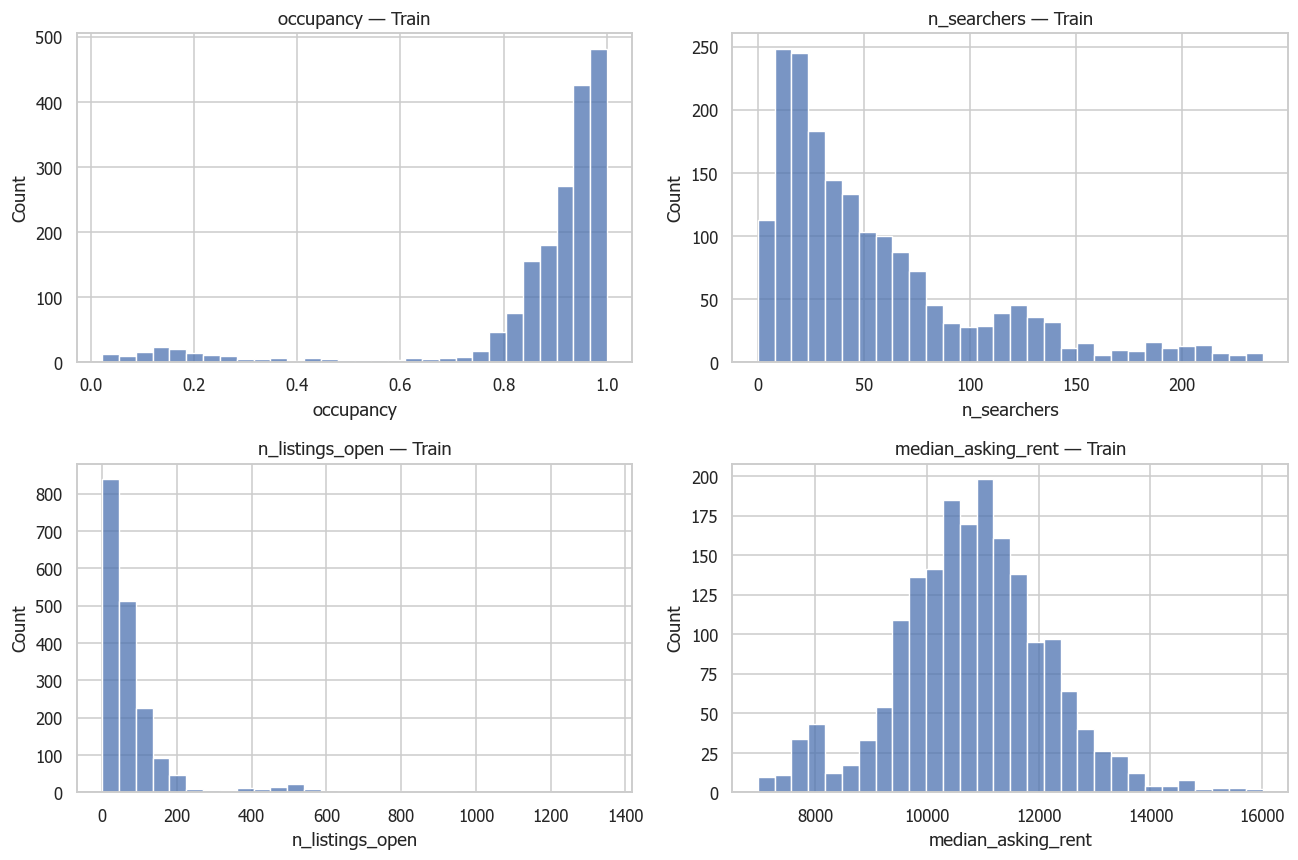

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for column, ax in zip(TARGET_COLUMNS, axes.flat):
    sns.histplot(data=eda_data, x=column, bins=30, ax=ax)
    ax.set_title(column + " — Train")
fig.tight_layout()
fig.savefig(REPORT_DIR / "01_target_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

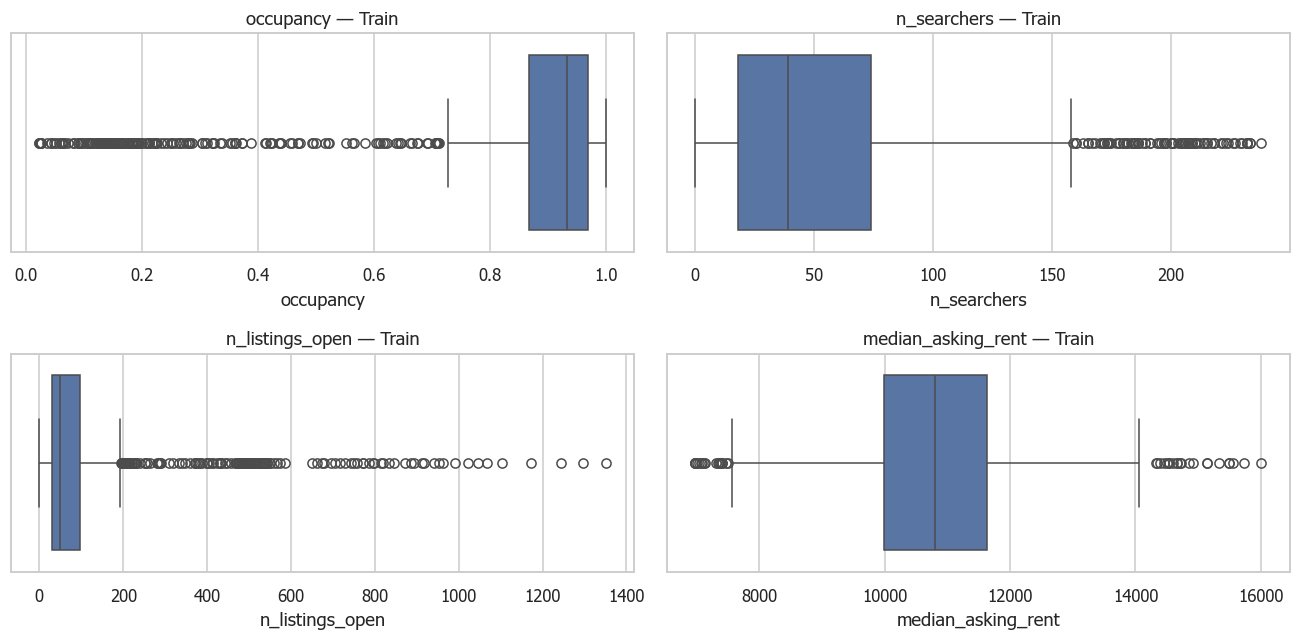

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(12, 6))
for column, ax in zip(TARGET_COLUMNS, axes.flat):
    sns.boxplot(data=eda_data, x=column, ax=ax)
    ax.set_title(column + " — Train")
fig.tight_layout()
fig.savefig(REPORT_DIR / "02_target_boxplots.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. แนวโน้ม occupancy แยกโครงการ

แยกกราฟแต่ละโครงการเพื่อไม่ให้เส้นทับกัน ใช้แกน y ช่วง 0–1 เหมือนกัน
ค่าเฉลี่ยรวมทุกโครงการอาจเปลี่ยนเพราะมีโครงการใหม่เข้ามา ไม่ใช่ตลาดทั้งหมดเปลี่ยน

,project_id,project_name,train_weeks,occupancy_mean,occupancy_min,occupancy_max,searchers_mean,asking_rent_median
0,0,Kave Condo,157,0.902436,0.791171,0.977929,33.216561,10290.0
1,1,Kave Town Space,157,0.944664,0.838770,0.993476,61.121019,10940.0
2,2,Kave Town Shift,157,0.940503,0.832246,0.993476,61.108280,11065.0
3,3,Kave Town Island,157,0.966163,0.838983,1.000000,101.171975,12147.5
4,4,Kave Town Colony,157,0.951321,0.837488,0.998153,62.248408,11760.0
5,5,Kave TU,157,0.951471,0.841535,0.995079,72.197452,11325.0
6,6,Kave Ava,157,0.964191,0.845070,0.999218,91.025478,11580.0
7,7,Kave Wonderland,53,0.740026,0.050597,1.000000,105.433962,11430.0
8,8,Kave Carnival,1,0.036471,0.036471,0.036471,33.000000,11240.0
9,9,Kave Embryo,105,0.765888,0.023346,0.970817,25.228571,9890.0


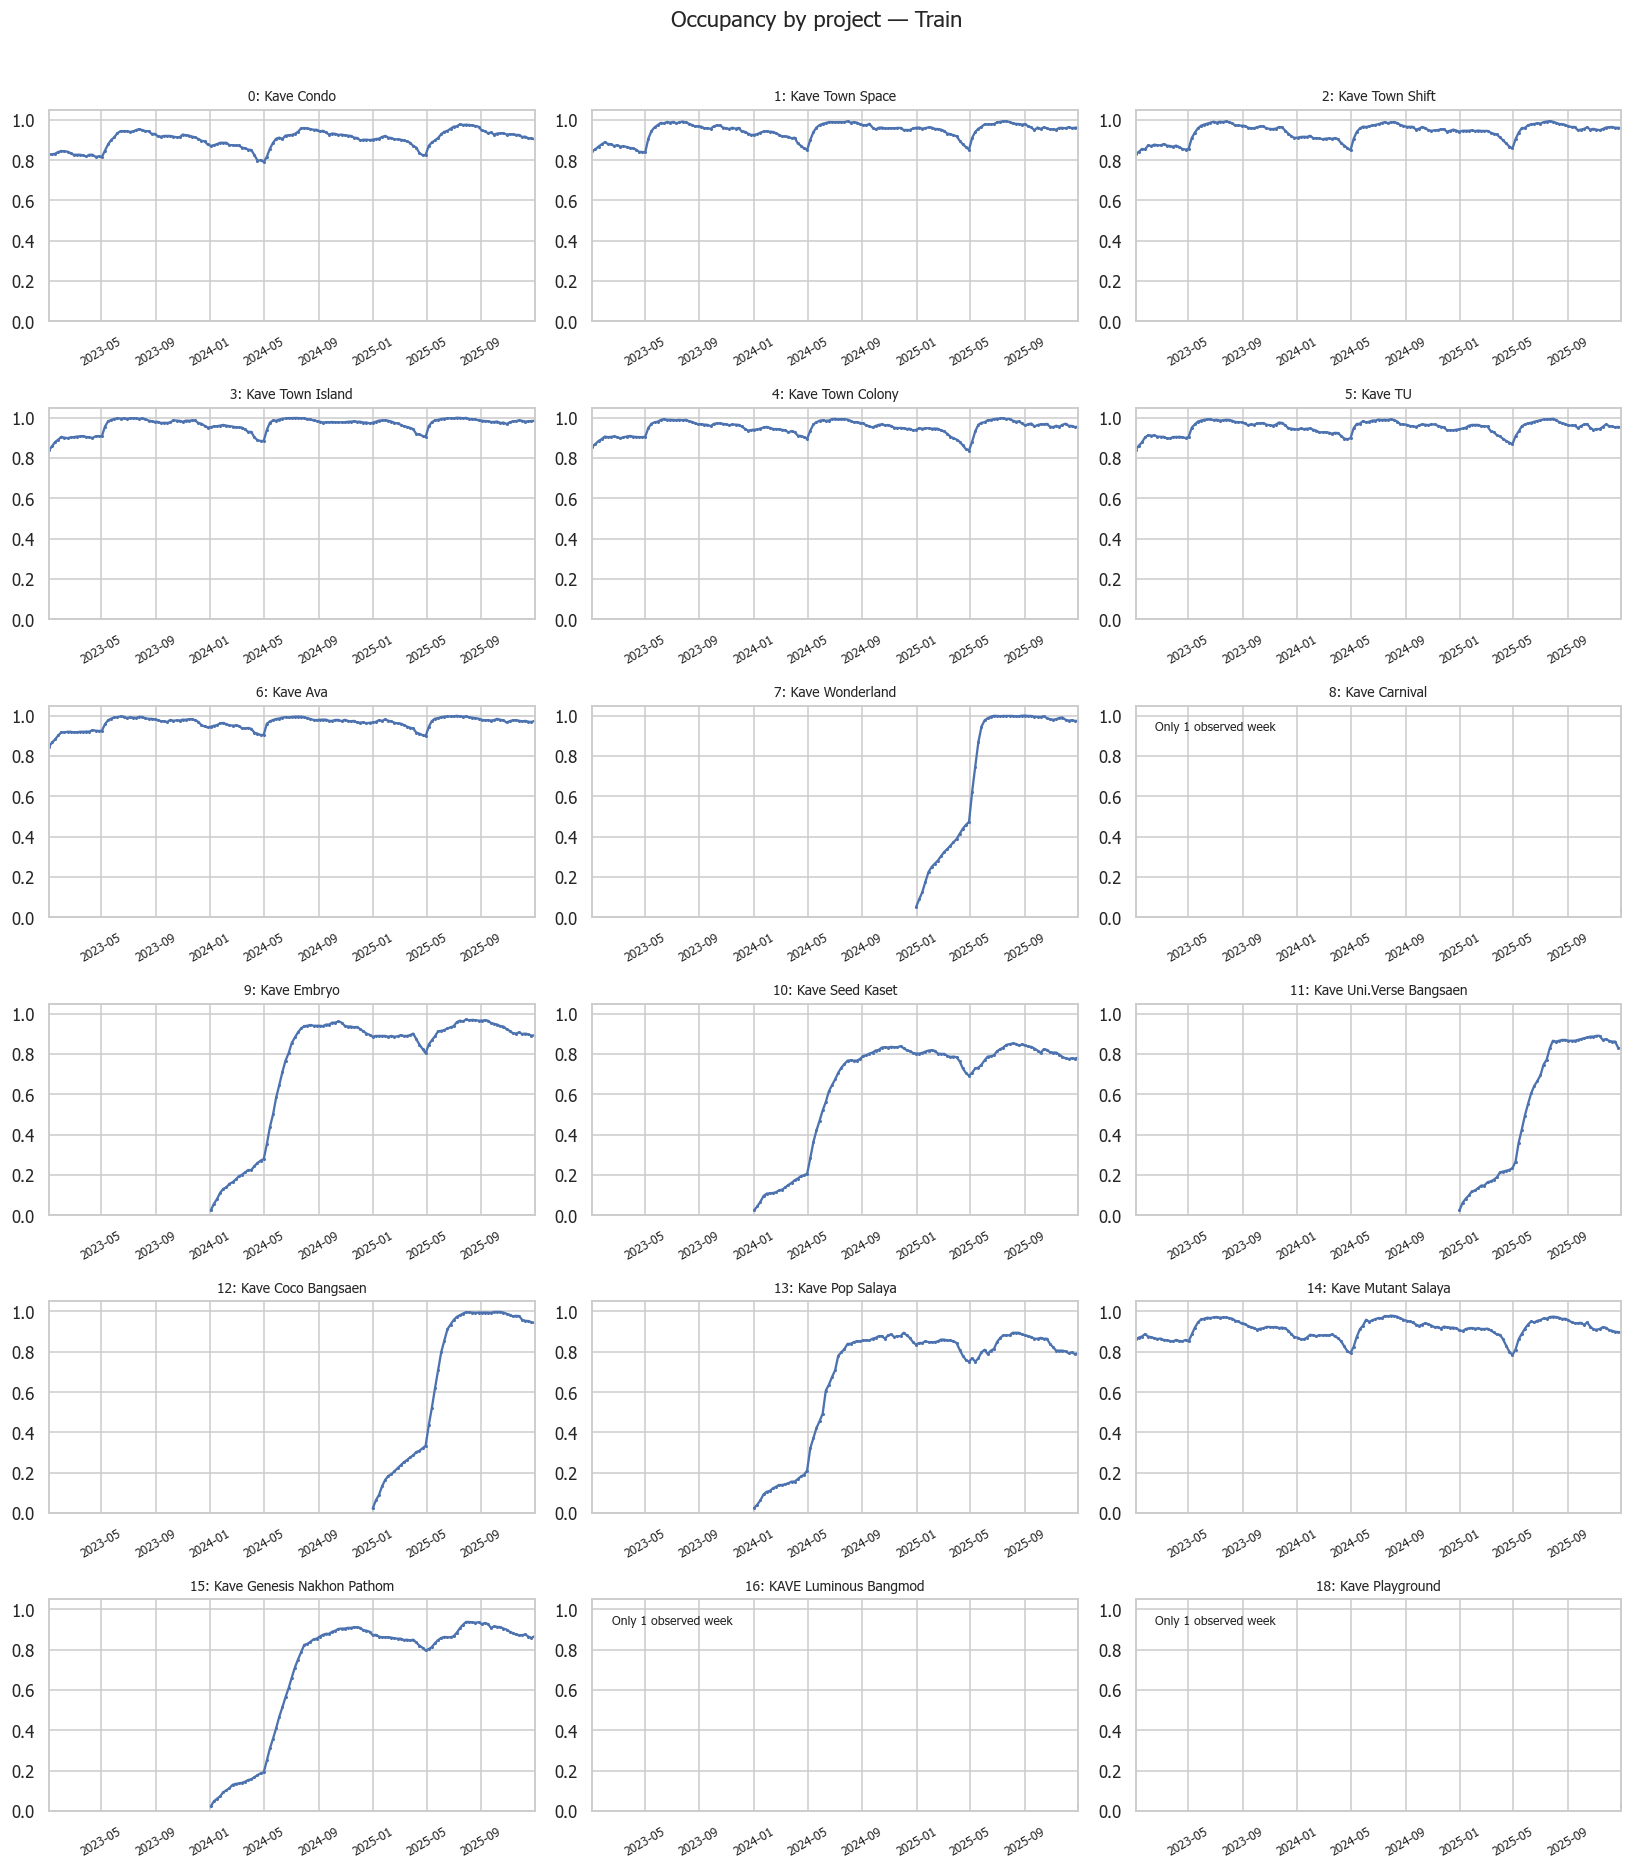

In [14]:
project_summary = eda_data.groupby(["project_id", "project_name"])
project_summary = project_summary.agg(train_weeks=("date", "size"), occupancy_mean=("occupancy", "mean"), occupancy_min=("occupancy", "min"), occupancy_max=("occupancy", "max"), searchers_mean=("n_searchers", "mean"), asking_rent_median=("median_asking_rent", "median"))
project_summary = project_summary.reset_index()
display(project_summary)

project_groups = list(eda_data.groupby(["project_id", "project_name"]))
number_of_rows = int(np.ceil(len(project_groups) / 3))
fig, axes = plt.subplots(number_of_rows, 3, figsize=(15, number_of_rows * 2.8), squeeze=False)
for ((project_id, project_name), frame), ax in zip(project_groups, axes.flat):
    ax.plot(frame["date"], frame["occupancy"], marker=".", markersize=2)
    ax.set_title(f"{project_id}: {project_name}", fontsize=9)
    ax.set_ylim(0, 1.05)
    ax.set_xlim(eda_data["date"].min(), eda_data["date"].max())
    if len(frame) == 1:
        ax.text(0.04, 0.88, "Only 1 observed week", transform=ax.transAxes, fontsize=8)
    ax.tick_params(axis="x", rotation=30, labelsize=8)
for ax in list(axes.flat)[len(project_groups):]:
    ax.set_visible(False)
fig.suptitle("Occupancy by project — Train", y=1.01)
fig.tight_layout()
fig.savefig(REPORT_DIR / "03_occupancy_by_project.png", dpi=150, bbox_inches="tight")
plt.show()

### แนวโน้มตลาดของโครงการกลุ่มเดิม

เลือกเฉพาะโครงการที่มีข้อมูลครบทุกวันที่อยู่ใน Train เพื่อให้สมาชิกกลุ่มคงเดิม
แสดงค่าเฉลี่ยแต่ละโครงการอย่างให้น้ำหนักเท่ากัน เป็นภาพของกลุ่มนี้เท่านั้น
ไม่เรียกค่าเฉลี่ยนี้ว่า occupancy รวมแบบถ่วงจำนวนห้อง

รหัสโครงการในกลุ่มคงเดิม: [0, 1, 2, 3, 4, 5, 6, 14]


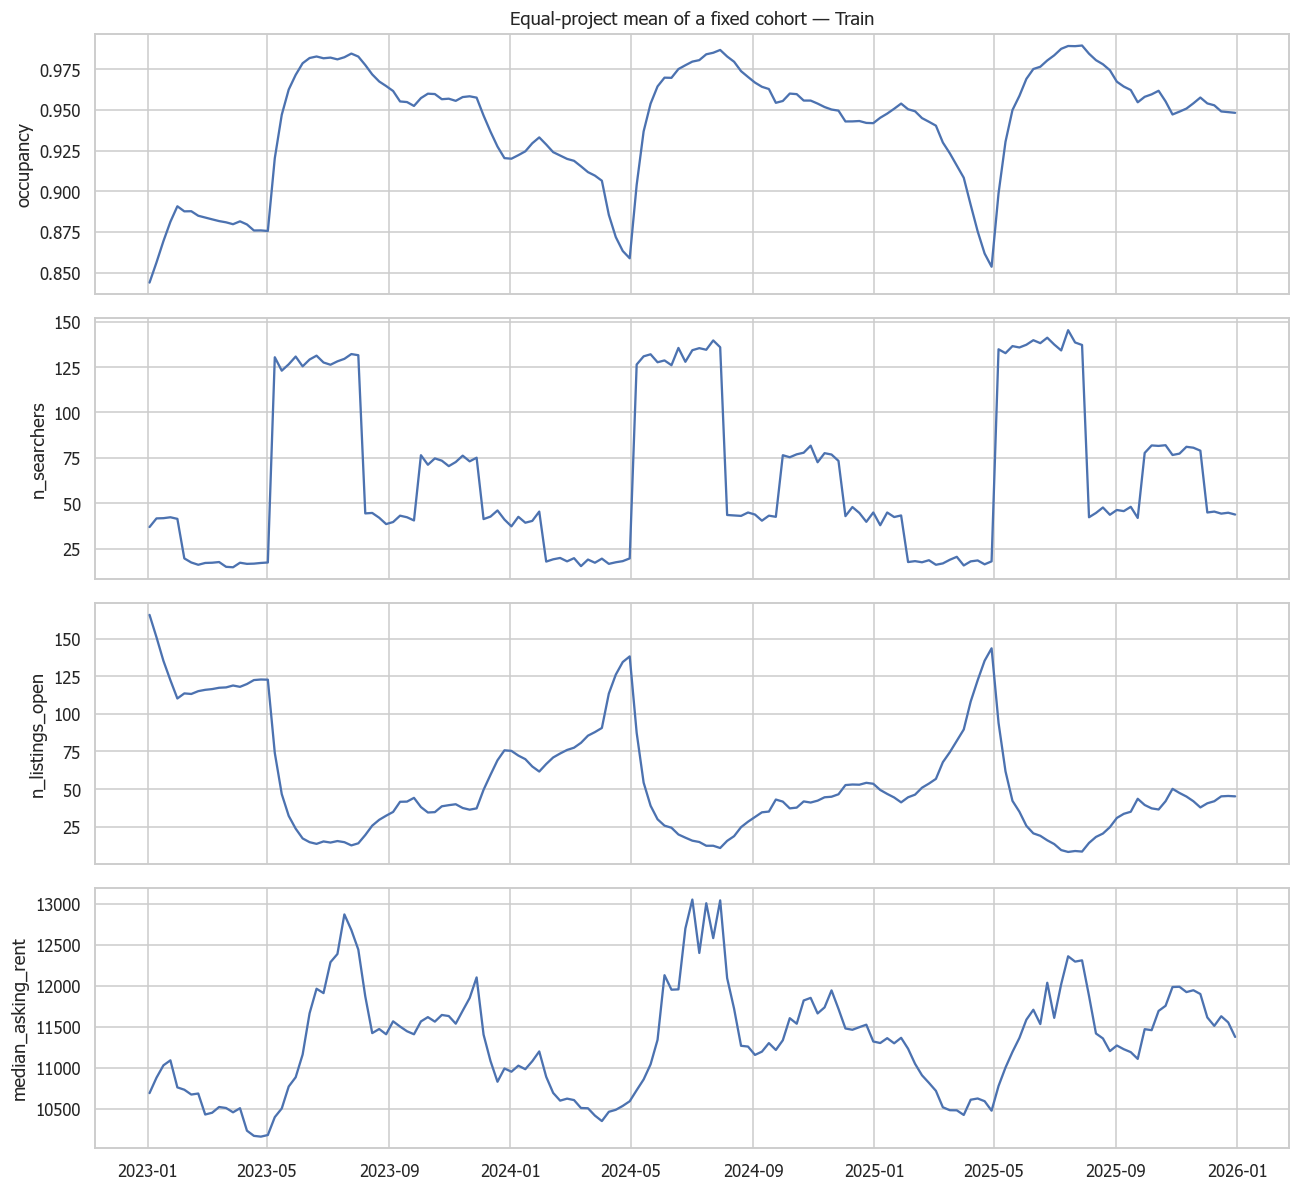

In [15]:
train_dates = eda_data["date"].nunique()
weeks_per_project = eda_data.groupby("project_id")["date"].nunique()
cohort_ids = weeks_per_project[(weeks_per_project == train_dates)].index
cohort_data = eda_data.loc[eda_data["project_id"].isin(cohort_ids)].copy()
if cohort_data.empty:
    raise ValueError("ไม่มีโครงการที่มีประวัติครบช่วง Train ต้องกำหนดกลุ่มเปรียบเทียบใหม่")

print("รหัสโครงการในกลุ่มคงเดิม:", list(cohort_ids))
cohort_trends = cohort_data.groupby("date")[TARGET_COLUMNS].mean()
fig, axes = plt.subplots(4, 1, figsize=(12, 11), sharex=True)
for column, ax in zip(TARGET_COLUMNS, axes):
    ax.plot(cohort_trends.index, cohort_trends[column])
    ax.set_ylabel(column)
axes[0].set_title("Equal-project mean of a fixed cohort — Train")
fig.tight_layout()
fig.savefig(REPORT_DIR / "04_fixed_cohort_trends.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. สำรวจฤดูกาลและเดือนใน Train

ใช้กลุ่มโครงการเดิมเพื่อลดปัญหาสมาชิกกลุ่มเปลี่ยน และแสดงจำนวนแถวในแต่ละกลุ่ม
ค่าเฉลี่ยตามเดือนไม่เพียงพอจะยืนยันฤดูกาล ต้องดูการเกิดซ้ำข้ามปีประกอบ

,rows,occupancy_mean,searchers_mean,listings_mean,asking_rent_mean
season,,,,,
normal,416,0.945951,43.009615,51.307692,11313.341346
off,312,0.899478,17.778846,98.253205,10562.115385
peak,312,0.968803,132.669872,26.467949,11808.344051
shoulder,216,0.955707,76.694444,40.351852,11724.722222


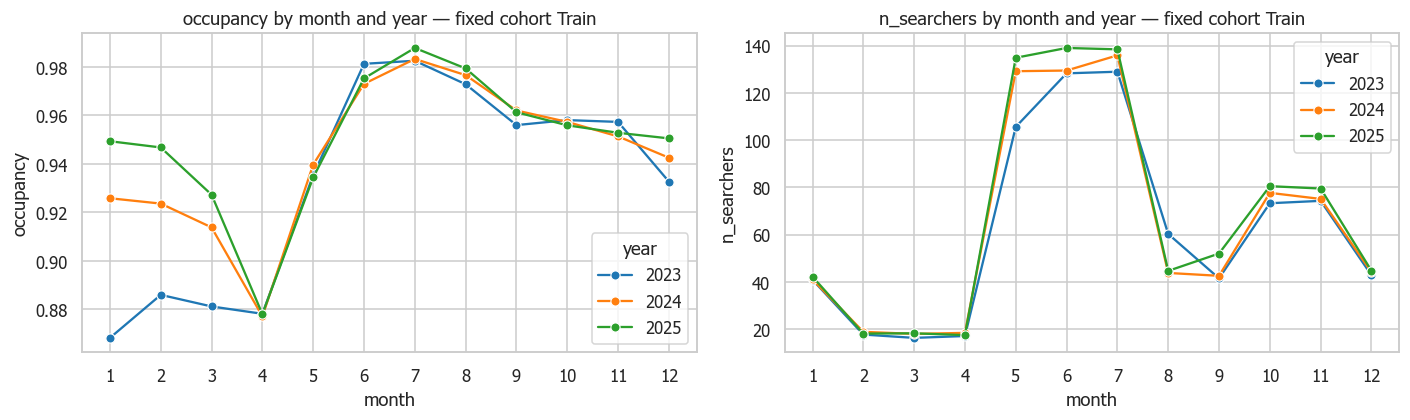

In [16]:
cohort_data["month"] = cohort_data["date"].dt.month
cohort_data["year"] = cohort_data["date"].dt.year
season_summary = cohort_data.groupby("season")
season_summary = season_summary.agg(rows=("date", "size"), occupancy_mean=("occupancy", "mean"), searchers_mean=("n_searchers", "mean"), listings_mean=("n_listings_open", "mean"), asking_rent_mean=("median_asking_rent", "mean"))
display(season_summary)

monthly_by_year = cohort_data.groupby(["year", "month"])[["occupancy", "n_searchers"]].mean()
monthly_by_year = monthly_by_year.reset_index()
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for column, ax in zip(["occupancy", "n_searchers"], axes):
    sns.lineplot(data=monthly_by_year, x="month", y=column, hue="year", palette="tab10", marker="o", ax=ax)
    ax.set_xticks(range(1, 13))
    ax.set_title(column + " by month and year — fixed cohort Train")
fig.tight_layout()
fig.savefig(REPORT_DIR / "05_monthly_patterns.png", dpi=150, bbox_inches="tight")
plt.show()

## 10. ความสัมพันธ์และข้อมูลย้อนหลัง

Correlation รวมอาจสะท้อนความต่างของขนาดโครงการ จึงแสดงเพิ่มหลังหักค่าเฉลี่ยแต่ละโครงการ
ความสัมพันธ์ไม่ยืนยันเหตุและผล และ `n_listings_open` กับ occupancy ณ เวลาเดียวกันมีสูตรผูกกัน
ห้ามใช้ค่าที่เกิด ณ target date มาทำนาย target date นั้น

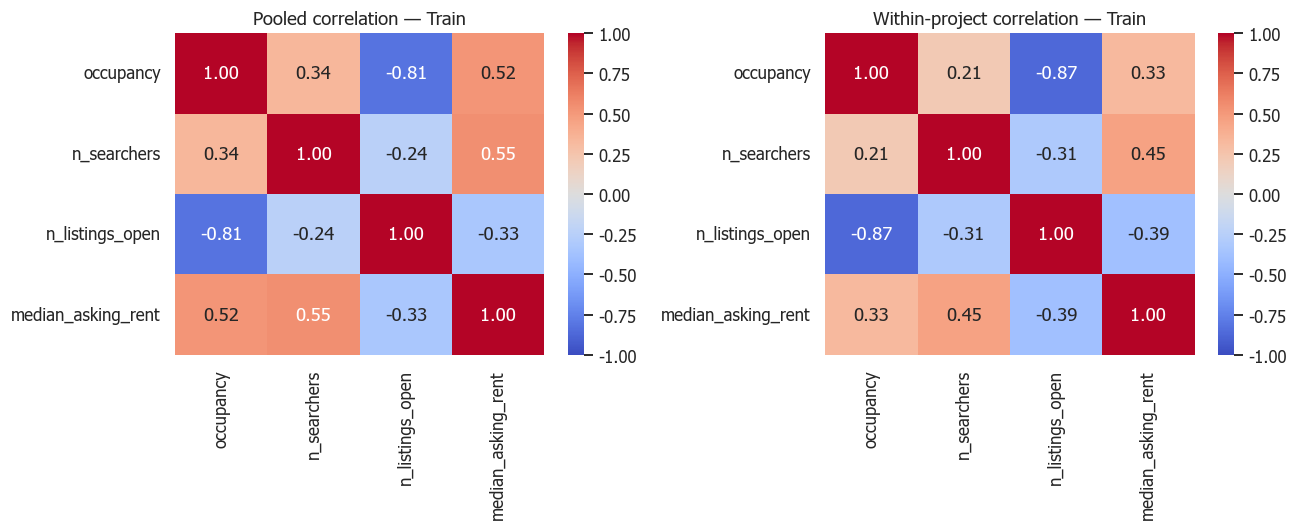

In [17]:
correlation_columns = TARGET_COLUMNS
pooled_correlation = eda_data[correlation_columns].corr()
project_means = eda_data.groupby("project_id")[correlation_columns].transform("mean")
within_project_values = eda_data[correlation_columns] - project_means
within_project_correlation = within_project_values.corr()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.heatmap(pooled_correlation, annot=True, fmt=".2f", vmin=-1, vmax=1, cmap="coolwarm", ax=axes[0])
sns.heatmap(within_project_correlation, annot=True, fmt=".2f", vmin=-1, vmax=1, cmap="coolwarm", ax=axes[1])
axes[0].set_title("Pooled correlation — Train")
axes[1].set_title("Within-project correlation — Train")
fig.tight_layout()
fig.savefig(REPORT_DIR / "06_correlations.png", dpi=150, bbox_inches="tight")
plt.show()

### เทียบ occupancy กับค่าก่อนหน้าโดยใช้วันที่จริง

ย้ายวันที่ของข้อมูลอดีตไปข้างหน้า แล้ว merge ตามโครงการและวันที่
จึงไม่เลื่อนแถวข้ามสัปดาห์ที่ขาด และไม่ปะปนโครงการ
ค่านี้ใช้สำรวจความต่อเนื่อง ไม่ใช่ผลคะแนนโมเดลพยากรณ์

In [18]:
lag_rows = []
for lag_weeks in [1, 4, 12, 52]:
    previous = eda_data[["project_id", "date", "occupancy"]].copy()
    previous["date"] = previous["date"] + pd.Timedelta(weeks=lag_weeks)
    previous = previous.rename(columns={"occupancy": "previous_occupancy"})
    pairs = eda_data[["project_id", "date", "occupancy"]].merge(previous, on=["project_id", "date"], how="inner", validate="one_to_one")
    for project_id, frame in pairs.groupby("project_id"):
        correlation = np.nan
        if len(frame) >= 3 and frame["occupancy"].nunique() > 1 and frame["previous_occupancy"].nunique() > 1:
            correlation = frame["occupancy"].corr(frame["previous_occupancy"])
        lag_rows.append({"project_id": project_id, "lag_weeks": lag_weeks, "pairs": len(frame), "correlation": correlation})

lag_summary = pd.DataFrame(lag_rows)
display(lag_summary)

,project_id,lag_weeks,pairs,correlation
0,0,1,156,0.971429
1,1,1,156,0.955777
2,2,1,156,0.961738
3,3,1,156,0.956681
4,4,1,156,0.953498
5,5,1,156,0.951081
6,6,1,156,0.951745
7,7,1,52,0.995679
8,9,1,104,0.997733
9,10,1,104,0.997906


## 11. ความพร้อมสำหรับ horizon 1, 4 และ 12 สัปดาห์

นับคู่วันออกรายงานและ target date ที่อยู่ภายใน Train โดยยังไม่ฝึกโมเดล
และนับเพิ่มเมื่อกำหนดว่าจะต้องมี occupancy ย้อนหลัง 12 สัปดาห์ครบทุกสัปดาห์
ค่านี้เป็นความพร้อมของคู่ข้อมูล ไม่ใช่จำนวน training rows สุดท้ายของทุก target

In [19]:
# นับคู่วันเริ่มพยากรณ์/วันคำตอบที่มีจริงใน Train
horizon_rows = []
for project_id, frame in eda_data.groupby("project_id"):
    dates = set(frame["date"])
    for horizon_weeks in [1, 4, 12]:
        origins = []
        origins_with_history = []
        for date in dates:
            answer_date = date + pd.Timedelta(weeks=horizon_weeks)
            if answer_date not in dates:
                continue
            origins.append(date)

            # ต้องมีข้อมูลครบทั้ง 12 สัปดาห์ก่อน origin
            has_history = True
            for lag in range(1, 13):
                previous_date = date - pd.Timedelta(weeks=lag)
                if previous_date not in dates:
                    has_history = False
                    break
            if has_history:
                origins_with_history.append(date)
        horizon_rows.append({
            "project_id": project_id, "horizon_weeks": horizon_weeks,
            "train_pairs": len(origins),
            "train_pairs_with_12_week_history": len(origins_with_history),
        })
horizon_readiness = pd.DataFrame(horizon_rows)
display(horizon_readiness)
is_one_week = horizon_readiness["horizon_weeks"] == 1
has_no_pairs = horizon_readiness["train_pairs"] == 0
no_training_projects = horizon_readiness.loc[is_one_week & has_no_pairs, "project_id"].tolist()
print("โครงการที่ไม่มีคู่ฝึกแม้แต่ horizon 1 สัปดาห์:", no_training_projects)

,project_id,horizon_weeks,train_pairs,train_pairs_with_12_week_history
0,0,1,156,144
1,0,4,153,141
2,0,12,145,133
3,1,1,156,144
4,1,4,153,141
5,1,12,145,133
6,2,1,156,144
7,2,4,153,141
8,2,12,145,133
9,3,1,156,144


โครงการที่ไม่มีคู่ฝึกแม้แต่ horizon 1 สัปดาห์: [8, 16, 18]


## 12. บันทึกผลและสรุปจากค่าที่คำนวณจริง

ผลสรุปสร้างจากตัวแปรที่รันด้านบน ไม่ใส่ผลตัวเลขไว้ล่วงหน้า
ไฟล์ CSV ใช้ตรวจและทำรายงานต่อได้ ไม่ใช่ชุดฝึกโมเดล

In [20]:
tables_to_save = {
    "data_inventory": inventory,
    "column_dictionary": dictionary,
    "missing_values": missing_table.reset_index(names="column"),
    "quality_checks": quality_checks,
    "capacity_checks": capacity_check,
    "identity_checks": identity_checks,
    "lease_reconciliation": lease_comparison,
    "weekly_coverage": coverage,
    "missing_weeks": missing_weeks,
    "split_overview": split_overview,
    "project_history": project_history,
    "train_target_statistics": target_statistics.reset_index(names="target"),
    "train_project_summary": project_summary,
    "train_fixed_cohort_trends": cohort_trends.reset_index(),
    "train_season_summary": season_summary.reset_index(),
    "train_monthly_by_year": monthly_by_year,
    "train_lag_correlations": lag_summary,
    "train_horizon_readiness": horizon_readiness,
}
for name, table in tables_to_save.items():
    table.to_csv(REPORT_DIR / f"{name}.csv", index=False, encoding="utf-8-sig")

In [21]:
short_history = project_history.loc[project_history["train_weeks"].between(1, 12), "project_id"].tolist()
no_market = coverage.loc[coverage["observed_weeks"].isna(), "project_id"].tolist()
missing_prices = market_data["median_asking_rent"].isna()
missing_prices = missing_prices.sum()
train_occupancy = eda_data["occupancy"]
lease_mismatch = (lease_comparison["difference_exclusive"] != 0).sum()

lag_medians = lag_summary.loc[(lag_summary["pairs"] >= 12)].groupby("lag_weeks")["correlation"].median()

summary = f"""# ผลตรวจข้อมูลและ EDA ตลาดและอัตราการเข้าพัก

คำนวณจาก data/processed ของโปรเจกต์ ซึ่งเป็นข้อมูลจำลอง
ใช้ทั้งชุดเฉพาะการตรวจโครงสร้าง; แนวโน้มและความสัมพันธ์ใช้ Train ถึง 31 ธันวาคม 2025

- weekly_market มี {len(market_data):,} แถว {market_data['project_id'].nunique()} โครงการ จาก projects ทั้งหมด {len(projects)} โครงการ
- ช่วงข้อมูล {market_data['date'].min():%Y-%m-%d} ถึง {market_data['date'].max():%Y-%m-%d}
- กฎคุณภาพหลักผิด {int(quality_checks['failures'].sum())} รายการ และสัปดาห์ที่ขาดภายในช่วงโครงการ {len(missing_weeks)} สัปดาห์
- median_asking_rent ว่าง {missing_prices} แถว; ตรวจว่าเกิดเฉพาะเมื่อไม่มีประกาศเปิด ไม่เติมศูนย์
- occupancy ไม่ตรงสูตร n_units_leased/total_units จำนวน {int(identity_checks.iloc[0]['failures'])} แถว
- occupancy ใน Train: เฉลี่ย {train_occupancy.mean():.2%}, มัธยฐาน {train_occupancy.median():.2%}, ต่ำสุด {train_occupancy.min():.2%}, สูงสุด {train_occupancy.max():.2%}; เป็นสถิติรายแถว ไม่ใช่อัตรารวมถ่วงจำนวนห้อง
- โครงการมีประวัติ Train ไม่เกิน 12 สัปดาห์: {short_history}
- โครงการไม่มีแถวตลาดในช่วงข้อมูล: {no_market}
- ห้องที่มีผู้เช่าจาก leases ไม่ตรง snapshot ตลาด {lease_mismatch:,} แถว เมื่อไม่รวม week_end; ต้องตรวจสัญญาก่อนช่วงข้อมูลและนิยามขอบเขตสัญญา

## สิ่งที่เห็นจาก EDA เฉพาะ Train

- กลุ่มโครงการเดิม {list(cohort_ids)} มีรูปแบบผู้ค้นหาสูงช่วงพฤษภาคม–กรกฎาคม และ occupancy สูงช่วงมิถุนายน–สิงหาคมซ้ำในปี 2023–2025 เป็นข้อสังเกตในข้อมูลจำลองนี้
- ฤดูกาล peak มีผู้ค้นหาเฉลี่ย {season_summary.loc['peak', 'searchers_mean']:.2f} รายต่อโครงการต่อสัปดาห์ และ occupancy เฉลี่ย {season_summary.loc['peak', 'occupancy_mean']:.2%}; off มี {season_summary.loc['off', 'searchers_mean']:.2f} ราย และ {season_summary.loc['off', 'occupancy_mean']:.2%} ตามลำดับ เฉพาะกลุ่มโครงการเดิม
- สหสัมพันธ์ occupancy กับราคาเสนอเช่า: รวม {pooled_correlation.loc['occupancy', 'median_asking_rent']:.2f}, หลังหักค่าเฉลี่ยโครงการ {within_project_correlation.loc['occupancy', 'median_asking_rent']:.2f}; ไม่ใช่หลักฐานว่าขึ้นราคาแล้ว occupancy จะเพิ่ม
- มัธยฐานสหสัมพันธ์รายโครงการกับ occupancy ย้อนหลัง 1 สัปดาห์ {lag_medians.get(1, float('nan')):.2f} และ 52 สัปดาห์ {lag_medians.get(52, float('nan')):.2f} โดยใช้โครงการที่มีอย่างน้อย 12 คู่ข้อมูลในแต่ละ lag เป็นสัญญาณให้ทดลอง baseline/lag features ต่อ ไม่ใช่คะแนนพยากรณ์

## ข้อสรุปสำหรับขั้นต่อไป

1. ใช้ occupancy ที่มีอยู่ใน weekly_market เป็น target ของข้อมูลจำลอง เพราะตรวจสูตรกับ total_units แล้ว; ไม่คำนวณทดแทนจาก leases จนกว่าจะตรวจความต่างได้
2. n_units_leased เป็นจำนวนห้องที่มีผู้เช่าอยู่ ไม่ใช่สัญญาใหม่; n_listings_open มีสูตรผูกกับ occupancy ณ สัปดาห์เดียวกัน
3. กลุ่มโครงการเริ่มใหม่มีช่วงสะสมผู้เช่าและประวัติสั้น ต้องวางวิธีรองรับก่อนฝึกโมเดลแยกรายโครงการ
4. ใช้กราฟรายโครงการและ fixed cohort ดูแนวโน้ม ลดการสรุปผิดจากสมาชิกตลาดเปลี่ยน
5. การสร้าง lag และ target ต้องจับคู่วันที่จริง เมื่อเตรียมชุดฝึกให้แบ่งตาม target_date และ fit preprocessing เฉพาะ Train
6. price target ที่ว่างจากไม่มีประกาศไม่ควรเติมศูนย์; ต้องกำหนดนโยบายฝึกและประเมินแยกจาก target อื่น
7. ยังไม่มีผลฝึกโมเดลหรือคะแนนพยากรณ์ในขั้นนี้ และไม่สรุปผลเชิงเหตุและผลจาก correlation
"""
(REPORT_DIR / "eda_summary.md").write_text(summary, encoding="utf-8")
display(Markdown(summary))
print("บันทึกตารางและกราฟแล้วที่:", REPORT_DIR)

# ผลตรวจข้อมูลและ EDA ตลาดและอัตราการเข้าพัก

คำนวณจาก data/processed ของโปรเจกต์ ซึ่งเป็นข้อมูลจำลอง
ใช้ทั้งชุดเฉพาะการตรวจโครงสร้าง; แนวโน้มและความสัมพันธ์ใช้ Train ถึง 31 ธันวาคม 2025

- weekly_market มี 2,288 แถว 18 โครงการ จาก projects ทั้งหมด 19 โครงการ
- ช่วงข้อมูล 2023-01-03 ถึง 2026-06-23
- กฎคุณภาพหลักผิด 0 รายการ และสัปดาห์ที่ขาดภายในช่วงโครงการ 0 สัปดาห์
- median_asking_rent ว่าง 3 แถว; ตรวจว่าเกิดเฉพาะเมื่อไม่มีประกาศเปิด ไม่เติมศูนย์
- occupancy ไม่ตรงสูตร n_units_leased/total_units จำนวน 0 แถว
- occupancy ใน Train: เฉลี่ย 86.22%, มัธยฐาน 93.26%, ต่ำสุด 2.25%, สูงสุด 100.00%; เป็นสถิติรายแถว ไม่ใช่อัตรารวมถ่วงจำนวนห้อง
- โครงการมีประวัติ Train ไม่เกิน 12 สัปดาห์: [8, 16, 18]
- โครงการไม่มีแถวตลาดในช่วงข้อมูล: [17]
- ห้องที่มีผู้เช่าจาก leases ไม่ตรง snapshot ตลาด 408 แถว เมื่อไม่รวม week_end; ต้องตรวจสัญญาก่อนช่วงข้อมูลและนิยามขอบเขตสัญญา

## สิ่งที่เห็นจาก EDA เฉพาะ Train

- กลุ่มโครงการเดิม [0, 1, 2, 3, 4, 5, 6, 14] มีรูปแบบผู้ค้นหาสูงช่วงพฤษภาคม–กรกฎาคม และ occupancy สูงช่วงมิถุนายน–สิงหาคมซ้ำในปี 2023–2025 เป็นข้อสังเกตในข้อมูลจำลองนี้
- ฤดูกาล peak มีผู้ค้นหาเฉลี่ย 132.67 รายต่อโครงการต่อสัปดาห์ และ occupancy เฉลี่ย 96.88%; off มี 17.78 ราย และ 89.95% ตามลำดับ เฉพาะกลุ่มโครงการเดิม
- สหสัมพันธ์ occupancy กับราคาเสนอเช่า: รวม 0.52, หลังหักค่าเฉลี่ยโครงการ 0.33; ไม่ใช่หลักฐานว่าขึ้นราคาแล้ว occupancy จะเพิ่ม
- มัธยฐานสหสัมพันธ์รายโครงการกับ occupancy ย้อนหลัง 1 สัปดาห์ 0.97 และ 52 สัปดาห์ 0.79 โดยใช้โครงการที่มีอย่างน้อย 12 คู่ข้อมูลในแต่ละ lag เป็นสัญญาณให้ทดลอง baseline/lag features ต่อ ไม่ใช่คะแนนพยากรณ์

## ข้อสรุปสำหรับขั้นต่อไป

1. ใช้ occupancy ที่มีอยู่ใน weekly_market เป็น target ของข้อมูลจำลอง เพราะตรวจสูตรกับ total_units แล้ว; ไม่คำนวณทดแทนจาก leases จนกว่าจะตรวจความต่างได้
2. n_units_leased เป็นจำนวนห้องที่มีผู้เช่าอยู่ ไม่ใช่สัญญาใหม่; n_listings_open มีสูตรผูกกับ occupancy ณ สัปดาห์เดียวกัน
3. กลุ่มโครงการเริ่มใหม่มีช่วงสะสมผู้เช่าและประวัติสั้น ต้องวางวิธีรองรับก่อนฝึกโมเดลแยกรายโครงการ
4. ใช้กราฟรายโครงการและ fixed cohort ดูแนวโน้ม ลดการสรุปผิดจากสมาชิกตลาดเปลี่ยน
5. การสร้าง lag และ target ต้องจับคู่วันที่จริง เมื่อเตรียมชุดฝึกให้แบ่งตาม target_date และ fit preprocessing เฉพาะ Train
6. price target ที่ว่างจากไม่มีประกาศไม่ควรเติมศูนย์; ต้องกำหนดนโยบายฝึกและประเมินแยกจาก target อื่น
7. ยังไม่มีผลฝึกโมเดลหรือคะแนนพยากรณ์ในขั้นนี้ และไม่สรุปผลเชิงเหตุและผลจาก correlation


บันทึกตารางและกราฟแล้วที่: D:\final project_\reports\market_occupancy\eda


# ส่วนที่ 2 เตรียมข้อมูลพยากรณ์ตลาดและอัตราการเข้าพัก

ต่อจาก EDA ในส่วนที่ 1 ใช้ข้อมูลจำลองใน `data/processed/` เตรียมสำหรับ **SARIMA, SARIMAX และ Random Forest**
พร้อม Naïve และ Seasonal Naïve เป็นวิธีพื้นฐานสำหรับเปรียบเทียบ ยังไม่ฝึกหรือเลือกโมเดล

อ่านและ Run All ตามลำดับ 12 ขั้นตอน โค้ดที่เรียกซ้ำแยกไว้ใน
`src/kaverentai/features/market_occupancy_features.py` มีคำอธิบายภาษาไทย
ส่วนนี้แสดงตัวอย่างก่อน–หลังแต่ละขั้นตอน

ใช้ `weekly_market_cleaned.csv` เป็นตารางหลัก และ `projects_cleaned.csv` เพิ่มข้อมูลโครงการ
ไม่ใช้ units/leases สร้าง occupancy ใหม่ เนื่องจาก EDA พบการนับสัญญายังไม่ตรง snapshot ตลาด

1, 4, 12 สัปดาห์เป็น **ช่วงทดลองของโครงงาน** ไม่ใช่ช่วงที่งานวิจัยกำหนดว่าเหมาะที่สุด
ผลข้อมูลอยู่ใน `data/modeling/market_occupancy/` และสรุปใน `reports/market_occupancy/features/`

## 1. Import และตั้งค่า

หาตำแหน่งโปรเจกต์อัตโนมัติ เปิดได้ทั้งจาก root และ notebooks
ใช้ไฟล์ config เดียวกันกำหนด horizon และวันแบ่งข้อมูล

In [22]:
from pathlib import Path
import json
import sys

import numpy as np
import pandas as pd
import yaml
from IPython.display import display, Markdown

In [23]:
PROJECT_ROOT = Path.cwd()
PROJECT_ROOT = PROJECT_ROOT.resolve()
while not (PROJECT_ROOT / "data" / "processed").is_dir():
    if PROJECT_ROOT == PROJECT_ROOT.parent:
        raise FileNotFoundError("เปิด Notebook ภายในโฟลเดอร์โปรเจกต์")
    PROJECT_ROOT = PROJECT_ROOT.parent

sys.path.insert(0, str(PROJECT_ROOT / "src"))
from kaverentai.features.market_occupancy_features import (
    TARGETS, LAGS, WINDOWS, prepare_weekly_panel, build_origin_features,
    build_forecast_pairs, label_time_splits, training_available_at_origin,
)

In [24]:
with (PROJECT_ROOT / "configs" / "model_config.yaml").open(encoding="utf-8") as file:
    config = yaml.safe_load(file)

HORIZONS = config["forecasting"]["horizons_weeks"]
TRAIN_END = config["time_split"]["train_end"]
VALIDATION_END = config["time_split"]["validation_end"]
TEST_END = config["forecasting"]["test_end"]
SEASONAL_PERIOD = config["forecasting"]["seasonal_period_weeks"]
MIN_SEASONAL_HISTORY = 2 * SEASONAL_PERIOD

MODEL_DATA_DIR = PROJECT_ROOT / "data" / "modeling" / "market_occupancy"
REPORT_DIR = PROJECT_ROOT / "reports" / "market_occupancy" / "features"
MODEL_DATA_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

print("Targets:", TARGETS)
print("Horizons:", HORIZONS)
print("Train / Validation / Test สิ้นสุด:", TRAIN_END, VALIDATION_END, TEST_END)

Targets: ['occupancy', 'n_searchers', 'n_listings_open', 'median_asking_rent']
Horizons: [1, 4, 12]
Train / Validation / Test สิ้นสุด: 2025-12-31 2026-03-31 2026-06-30


## 2. โหลดเฉพาะข้อมูลที่ใช้จริง

ขั้นเตรียมข้อมูลใช้ 2 ไฟล์ และไม่แก้ CSV ต้นฉบับ
วัน `date` ถือเป็นวันออกรายงานที่ตัวเลขสัปดาห์นั้นพร้อมใช้แล้ว
ถ้าใช้งานจริงมีความล่าช้าในการรายงาน ต้องเพิ่ม available_at และเลื่อน input ตามเวลาที่ได้รับจริง

In [25]:
DATA_DIR = PROJECT_ROOT / "data" / "processed"
weekly = pd.read_csv(DATA_DIR / "weekly_market_cleaned.csv")
projects = pd.read_csv(DATA_DIR / "projects_cleaned.csv")

display(weekly.head())
display(projects[["project_id", "project_name", "total_units"]].head())
print("weekly_market:", len(weekly), "แถว")
print("projects:", len(projects), "โครงการ")

,week,date,project_id,season,n_searchers,n_listings_open,n_units_leased,occupancy,median_asking_rent
0,0,2023-01-03,0,normal,21,101,488,0.828523,10010.0
1,0,2023-01-03,1,normal,39,166,907,0.845294,10480.0
2,0,2023-01-03,2,normal,36,180,893,0.832246,10965.0
3,0,2023-01-03,3,normal,55,285,1485,0.838983,11110.0
4,0,2023-01-03,4,normal,40,155,928,0.856879,11260.0


,project_id,project_name,total_units
0,0,Kave Condo,589
1,1,Kave Town Space,1073
2,2,Kave Town Shift,1073
3,3,Kave Town Island,1770
4,4,Kave Town Colony,1083


weekly_market: 2288 แถว
projects: 19 โครงการ


## 3. จัดตารางรายสัปดาห์แยกโครงการ

ฟังก์ชัน prepare_weekly_panel ทำ 3 อย่าง:
1. ตรวจ date และ key ซ้ำ
2. สร้างตารางวันที่ห่างกัน 7 วันภายในช่วงของแต่ละโครงการ หากสัปดาห์หายให้เป็นแถว NaN
3. เชื่อมชื่อโครงการและจำนวนห้องแบบ many-to-one

ไม่สร้างสัปดาห์ก่อนที่โครงการมีข้อมูล และไม่ใช้ shift ข้ามโครงการ

In [26]:
# prepare_weekly_panel เชื่อมรายสัปดาห์กับข้อมูลโครงการ และคงสัปดาห์ขาดเป็น NaN
panel = prepare_weekly_panel(weekly, projects)

panel_overview = panel.groupby("project_id")
panel_overview = panel_overview.agg(first_date=("date", "min"), last_date=("date", "max"), weekly_rows=("date", "size"), observed_weeks=("is_observed_week", "sum"))
panel_overview = panel_overview.reset_index()
panel_overview["missing_weeks"] = panel_overview["weekly_rows"] - panel_overview["observed_weeks"]
display(panel_overview)
display(panel[["project_id", "date", "project_name"] + TARGETS].head())
assert not panel.duplicated(["project_id", "date"]).any()

,project_id,first_date,last_date,weekly_rows,observed_weeks,missing_weeks
0,0,2023-01-03,2026-06-23,182,182,0
1,1,2023-01-03,2026-06-23,182,182,0
2,2,2023-01-03,2026-06-23,182,182,0
3,3,2023-01-03,2026-06-23,182,182,0
4,4,2023-01-03,2026-06-23,182,182,0
5,5,2023-01-03,2026-06-23,182,182,0
6,6,2023-01-03,2026-06-23,182,182,0
7,7,2024-12-31,2026-06-23,78,78,0
8,8,2025-12-30,2026-06-23,26,26,0
9,9,2024-01-02,2026-06-23,130,130,0


,project_id,date,project_name,occupancy,n_searchers,n_listings_open,median_asking_rent
0,0,2023-01-03,Kave Condo,0.828523,21,101,10010.0
1,0,2023-01-10,Kave Condo,0.828523,22,101,10050.0
2,0,2023-01-17,Kave Condo,0.831919,17,99,10060.0
3,0,2023-01-24,Kave Condo,0.840407,20,94,10135.0
4,0,2023-01-31,Kave Condo,0.845501,20,91,9930.0


## 4. จัดการราคาเสนอเช่าที่ว่างอย่างแยกหน้าที่

สร้าง `asking_rent_input` ด้วย forward fill ภายในโครงการ ใช้เฉพาะราคาที่เคยรู้แล้ว
เก็บ `asking_rent_missing_at_origin` เพื่อบอกว่า ณ สัปดาห์นี้ไม่มีราคาจริง
คอลัมน์ `median_asking_rent` เดิมยังคงว่างเพื่อไม่แต่งคำตอบสำหรับประเมิน

`build_origin_features` สร้างตัวแปรย้อนหลังในขั้น 5 พร้อมกัน ส่วนนี้ตรวจผลการเติมราคาให้เห็นก่อน

In [27]:
# build_origin_features คืน 3 ค่า: ตาราง features, ชื่อตัวเลข, ชื่อหมวดหมู่; รายละเอียดอยู่ไฟล์ features
origin_features, numeric_features, categorical_features = build_origin_features(panel)
missing_price_examples = origin_features.loc[
    origin_features["median_asking_rent"].isna(),
    ["project_id", "date", "n_listings_open", "median_asking_rent", "asking_rent_input", "asking_rent_missing_at_origin"],
]
display(missing_price_examples)

# ตรวจว่าราคา target เดิมไม่ได้ถูกเติม
assert origin_features["median_asking_rent"].isna().sum() == panel["median_asking_rent"].isna().sum()

,project_id,date,n_listings_open,median_asking_rent,asking_rent_input,asking_rent_missing_at_origin
677,3,2025-07-08,0,NaN,11910.0,1
1308,7,2025-08-26,0,NaN,13285.0,1
1309,7,2025-09-02,0,NaN,13285.0,1


## 5. ดูตัวแปรย้อนหลังสำหรับ Random Forest

- `_current`: ค่าที่รู้ ณ origin
- `_lag_1 / 4 / 12`: ค่าเมื่อ 1 / 4 / 12 สัปดาห์ก่อน
- `_rolling_mean_4 / 12`: ค่าเฉลี่ย 4 / 12 สัปดาห์ก่อน origin **ไม่รวมสัปดาห์ปัจจุบัน**

ตัวอย่าง ถ้า origin คือ 2 เมษายน ค่า lag_1 มาจาก 26 มีนาคม
rolling_mean_4 มาจาก 4 สัปดาห์ก่อน 2 เมษายน ไม่อ่านข้อมูลหลัง origin
จำนวน lag/window เป็นตัวเลือกเริ่มต้นที่ต้องตรวจด้วย Validation ภายหลัง

ถ้าราคา input ยังว่างก่อนมีราคาครั้งแรก จะคง NaN ให้ขั้นฝึก fit imputer บนชุดฝึกของรอบนั้น
ไม่คำนวณ median หรือ scaling จากข้อมูลทั้งชุดใน Notebook นี้

In [28]:
example_columns = [
    "project_id", "date", "occupancy_current", "occupancy_lag_1",
    "occupancy_lag_4", "occupancy_lag_12", "occupancy_rolling_mean_4",
    "occupancy_rolling_mean_12", "history_complete_12",
]
example_project = origin_features["project_id"].min()
display(origin_features.loc[(origin_features["project_id"] == example_project), example_columns].head(16))
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

,project_id,date,occupancy_current,occupancy_lag_1,occupancy_lag_4,occupancy_lag_12,occupancy_rolling_mean_4,occupancy_rolling_mean_12,history_complete_12
0,0,2023-01-03,0.828523,NaN,NaN,NaN,NaN,NaN,False
1,0,2023-01-10,0.828523,0.828523,NaN,NaN,NaN,NaN,False
2,0,2023-01-17,0.831919,0.828523,NaN,NaN,NaN,NaN,False
3,0,2023-01-24,0.840407,0.831919,NaN,NaN,NaN,NaN,False
4,0,2023-01-31,0.845501,0.840407,0.828523,NaN,0.832343,NaN,False
5,0,2023-02-07,0.843803,0.845501,0.828523,NaN,0.836587,NaN,False
6,0,2023-02-14,0.842105,0.843803,0.831919,NaN,0.840407,NaN,False
7,0,2023-02-21,0.833616,0.842105,0.840407,NaN,0.842954,NaN,False
8,0,2023-02-28,0.826825,0.833616,0.845501,NaN,0.841256,NaN,False
9,0,2023-03-07,0.826825,0.826825,0.843803,NaN,0.836587,NaN,False


Numeric features: ['total_units', 'distance_to_campus_m', 'facility_count', 'asking_rent_missing_at_origin', 'occupancy_current', 'occupancy_lag_1', 'occupancy_lag_4', 'occupancy_lag_12', 'occupancy_rolling_mean_4', 'occupancy_rolling_mean_12', 'n_searchers_current', 'n_searchers_lag_1', 'n_searchers_lag_4', 'n_searchers_lag_12', 'n_searchers_rolling_mean_4', 'n_searchers_rolling_mean_12', 'n_listings_open_current', 'n_listings_open_lag_1', 'n_listings_open_lag_4', 'n_listings_open_lag_12', 'n_listings_open_rolling_mean_4', 'n_listings_open_rolling_mean_12', 'median_asking_rent_current', 'median_asking_rent_lag_1', 'median_asking_rent_lag_4', 'median_asking_rent_lag_12', 'median_asking_rent_rolling_mean_4', 'median_asking_rent_rolling_mean_12', 'observed_weeks_at_origin', 'origin_month', 'origin_year']
Categorical features: ['project_key', 'university', 'season']


## 6. สร้างเป้าหมายด้วยวันที่จริง

กำหนด `target_date = forecast_origin + horizon` แล้ว merge คำตอบจากโครงการและวันที่นั้น
เก็บคำตอบ 4 ตัวเป็น `y_...` และไม่เติมค่าว่าง target
`target_month_sin/cos` เป็นเดือนของวันเป้าหมายที่ทราบล่วงหน้าจากปฏิทิน
ไม่ใช้ season ในอนาคตจาก CSV เป็น input

In [29]:
# สร้างคำตอบของแต่ละ horizon แล้วแบ่งชุดตาม target_date; dictionary เก็บตารางแยก horizon
pairs_by_horizon = {}
for horizon in HORIZONS:
    pairs = build_forecast_pairs(origin_features, panel, horizon)
    pairs = label_time_splits(pairs, TRAIN_END, VALIDATION_END, TEST_END)
    pairs_by_horizon[horizon] = pairs

preview = pairs_by_horizon[4][[
    "project_id", "forecast_origin", "target_date", "horizon_weeks",
    "occupancy_current", "y_occupancy", "split",
]]
display(preview.head(8))

for horizon, pairs in pairs_by_horizon.items():
    assert (pairs["target_date"] - pairs["forecast_origin"] == pd.Timedelta(weeks=horizon)).all()

,project_id,forecast_origin,target_date,horizon_weeks,occupancy_current,y_occupancy,split
0,0,2023-01-03,2023-01-31,4,0.828523,0.845501,Train
1,0,2023-01-10,2023-02-07,4,0.828523,0.843803,Train
2,0,2023-01-17,2023-02-14,4,0.831919,0.842105,Train
3,0,2023-01-24,2023-02-21,4,0.840407,0.833616,Train
4,0,2023-01-31,2023-02-28,4,0.845501,0.826825,Train
5,0,2023-02-07,2023-03-07,4,0.843803,0.826825,Train
6,0,2023-02-14,2023-03-14,4,0.842105,0.826825,Train
7,0,2023-02-21,2023-03-21,4,0.833616,0.823430,Train


## 7. เตรียมตาราง Random Forest แยก target และ horizon

ใช้เฉพาะ origin ที่เป็นสัปดาห์จริง มี occupancy ย้อนหลังครบ 12 สัปดาห์ และมีคำตอบของ target นั้น
ถ้าราคา target ว่าง ตัดเฉพาะงานพยากรณ์ราคา ไม่ลบแถวนั้นจากงาน occupancy/ผู้ค้นหา/ประกาศ
ท้ายข้อมูลที่ยังไม่มีคำตอบในอนาคตยังไม่ใช่ตัวอย่างฝึก และถูกนับในรายงานการคัดแถว

เลือก input ด้วยรายการชื่อที่กำหนดเท่านั้น ห้ามเลือกทุกคอลัมน์อัตโนมัติ เพราะตารางคู่มีคำตอบอนาคตอยู่ด้วย

In [30]:
# is_observed_week และ history_complete_12 เป็นเงื่อนไขที่ใช้กรอง origin ของ Random Forest
calendar_features = ["target_month_sin", "target_month_cos"]
rf_features = numeric_features + categorical_features + calendar_features
date_columns = ["project_id", "forecast_origin", "target_date", "horizon_weeks", "split"]
rf_datasets = {}
row_selection = []

for horizon, pairs in pairs_by_horizon.items():
    valid_origin = pairs["is_observed_week"] & pairs["history_complete_12"]
    inside_period = (pairs["split"] != "outside_period")
    for target in TARGETS:
        has_answer = pairs[f"y_{target}"].notna()
        keep = valid_origin & inside_period & has_answer
        dataset = pairs.loc[keep, date_columns + rf_features + [f"y_{target}"]].copy()
        dataset = dataset.rename(columns={f"y_{target}": "y"})
        rf_datasets[(target, horizon)] = dataset
        row_selection.append({
            "target": target, "horizon_weeks": horizon,
            "total_origins": len(pairs),
            "invalid_or_short_history": int((~valid_origin).sum()),
            "outside_period_after_history": int((valid_origin & ~inside_period).sum()),
            "missing_target_inside_period": int((valid_origin & inside_period & ~has_answer).sum()),
            "kept_rows": len(dataset),
        })

row_selection = pd.DataFrame(row_selection)
display(row_selection)
display(rf_datasets[("occupancy", 4)].head())
assert not any(column.startswith("y_") for column in rf_features)

,target,horizon_weeks,total_origins,invalid_or_short_history,outside_period_after_history,missing_target_inside_period,kept_rows
0,occupancy,1,2288,216,0,18,2054
1,n_searchers,1,2288,216,0,18,2054
2,n_listings_open,1,2288,216,0,18,2054
3,median_asking_rent,1,2288,216,0,21,2051
4,occupancy,4,2288,216,54,18,2000
5,n_searchers,4,2288,216,54,18,2000
6,n_listings_open,4,2288,216,54,18,2000
7,median_asking_rent,4,2288,216,54,21,1997
8,occupancy,12,2288,216,198,18,1856
9,n_searchers,12,2288,216,198,18,1856


,project_id,forecast_origin,target_date,horizon_weeks,split,total_units,distance_to_campus_m,facility_count,asking_rent_missing_at_origin,occupancy_current,occupancy_lag_1,occupancy_lag_4,occupancy_lag_12,occupancy_rolling_mean_4,occupancy_rolling_mean_12,n_searchers_current,n_searchers_lag_1,n_searchers_lag_4,n_searchers_lag_12,n_searchers_rolling_mean_4,n_searchers_rolling_mean_12,n_listings_open_current,n_listings_open_lag_1,n_listings_open_lag_4,n_listings_open_lag_12,n_listings_open_rolling_mean_4,n_listings_open_rolling_mean_12,median_asking_rent_current,median_asking_rent_lag_1,median_asking_rent_lag_4,median_asking_rent_lag_12,median_asking_rent_rolling_mean_4,median_asking_rent_rolling_mean_12,observed_weeks_at_origin,origin_month,origin_year,project_key,university,season,target_month_sin,target_month_cos,y
12,0,2023-03-28,2023-04-25,4,Train,589,100,20,0,0.818336,0.823430,0.826825,0.828523,0.825976,0.833192,10,7.0,7.0,21.0,8.50,13.250000,107,104.0,102.0,101.0,102.50,98.250000,9430.0,9550.0,9480.0,10010.0,9546.25,9820.416667,13,3,2023,0,ม.กรุงเทพ,off,1.000000,6.123234e-17,0.818336
13,0,2023-04-04,2023-05-02,4,Train,589,100,20,0,0.826825,0.818336,0.826825,0.828523,0.823854,0.832343,13,10.0,8.0,22.0,9.25,12.333333,102,107.0,102.0,101.0,103.75,98.750000,9695.0,9430.0,9550.0,10050.0,9533.75,9772.083333,14,4,2023,0,ม.กรุงเทพ,off,0.866025,-5.000000e-01,0.814941
14,0,2023-04-11,2023-05-09,4,Train,589,100,20,0,0.826825,0.826825,0.826825,0.831919,0.823854,0.832201,12,13.0,12.0,17.0,10.50,11.583333,102,102.0,102.0,99.0,103.75,98.833333,9405.0,9695.0,9605.0,10060.0,9570.00,9742.500000,15,4,2023,0,ม.กรุงเทพ,off,0.866025,-5.000000e-01,0.847199
15,0,2023-04-18,2023-05-16,4,Train,589,100,20,0,0.816638,0.826825,0.823430,0.840407,0.823854,0.831777,8,12.0,7.0,20.0,10.50,11.166667,108,102.0,104.0,94.0,103.75,99.083333,9315.0,9405.0,9550.0,10135.0,9520.00,9687.916667,16,4,2023,0,ม.กรุงเทพ,off,0.866025,-5.000000e-01,0.877759
16,0,2023-04-25,2023-05-23,4,Train,589,100,20,0,0.818336,0.816638,0.818336,0.845501,0.822156,0.829796,11,8.0,10.0,20.0,10.75,10.166667,107,108.0,107.0,91.0,104.75,100.250000,9400.0,9315.0,9430.0,9930.0,9461.25,9619.583333,17,4,2023,0,ม.กรุงเทพ,off,0.866025,-5.000000e-01,0.899830


## 8. เตรียมอนุกรมเวลาสำหรับ SARIMA และ Seasonal Naïve

SARIMA ใช้ y รายสัปดาห์แยกโครงการ ไม่ใช้ตาราง lag ของ Random Forest
คงราคา y ที่ว่างไว้ state-space fitting ต้องจัดการ missing endog ในขั้นฝึก โดยไม่เติมคำตอบสำหรับประเมิน

ทดลองฤดูกาล 52 สัปดาห์เป็นประมาณหนึ่งปี ไม่ใช่ horizon และไม่ใช่ข้อกำหนดจากงานวิจัย
สำหรับการเปรียบเทียบหลัก กำหนดประวัติอย่างน้อย 2 รอบ หรือ 104 จุดที่มี y เป็นเกณฑ์เริ่มต้นแบบระมัดระวัง
เกณฑ์นี้เป็นการออกแบบโครงงาน ไม่ใช่หลักประกันว่าฝึกได้หรือแม่น ต้องตรวจการลู่เข้าและ Validation อีกครั้ง
โครงการที่มีข้อมูลน้อยกว่าจะรายงานแยกในกลุ่มประวัติสั้น

In [31]:
sarima_series = panel[["project_id", "date", "is_observed_week"] + TARGETS].copy()
sarima_series["split"] = "Test"
sarima_series.loc[(sarima_series["date"] <= pd.Timestamp(VALIDATION_END)), "split"] = "Validation"
sarima_series.loc[(sarima_series["date"] <= pd.Timestamp(TRAIN_END)), "split"] = "Train"

display(sarima_series.head())
print("Seasonal period ทดลอง:", SEASONAL_PERIOD, "สัปดาห์")
print("ประวัติขั้นต่ำสำหรับการเปรียบเทียบหลัก:", MIN_SEASONAL_HISTORY, "จุดที่มี y")

# เมื่อเริ่มพยากรณ์จริงต้องตัดอนุกรมเวลาที่ date <= origin เสมอ
example_origin = pd.Timestamp("2025-10-14")
example_series = sarima_series.loc[
    (sarima_series["project_id"] == example_project) & (sarima_series["date"] <= example_origin),
    ["date", "occupancy"],
].set_index("date")
example_series = example_series.asfreq("7D")
display(example_series.tail())
assert example_series.index.max() <= example_origin

,project_id,date,is_observed_week,occupancy,n_searchers,n_listings_open,median_asking_rent,split
0,0,2023-01-03,True,0.828523,21,101,10010.0,Train
1,0,2023-01-10,True,0.828523,22,101,10050.0,Train
2,0,2023-01-17,True,0.831919,17,99,10060.0,Train
3,0,2023-01-24,True,0.840407,20,94,10135.0,Train
4,0,2023-01-31,True,0.845501,20,91,9930.0,Train


Seasonal period ทดลอง: 52 สัปดาห์
ประวัติขั้นต่ำสำหรับการเปรียบเทียบหลัก: 104 จุดที่มี y


,occupancy
date,
2025-09-16,0.933786
2025-09-23,0.937182
2025-09-30,0.926995
2025-10-07,0.932088
2025-10-14,0.933786


## 9. เตรียมตัวแปรภายนอกสำหรับ SARIMAX แบบใช้ได้ ณ origin

สร้างแบบจำลองแยกแต่ละ horizon: สำหรับ y ณ วัน t ใช้ตลาดที่ทราบ ณ t−h
occupancy ใช้จำนวนผู้ค้นหาและราคา ส่วน target อื่นใช้ occupancy และราคา/ผู้ค้นหาที่ไม่ใช่ตัว target เอง
ไม่ใส่ n_listings_open เป็นตัวประกอบของ occupancy เพราะในข้อมูลนี้มีสูตรผูกกันโดยตรง

เพิ่มเดือนเป้าหมายจากปฏิทิน ตอนพยากรณ์ h ก้าวต้องส่ง exog ครบทุกก้าว ไม่ใช่แค่วันสุดท้าย
ตัวอย่างนี้เลื่อนข้อมูลประกอบย้อนหลัง h สัปดาห์ จึงรู้ค่าตลอดเส้นทางโดยไม่ต้องหยิบค่าตลาดในอนาคตจริง
ตารางฝึกมี y แต่ **ตาราง exog ที่ส่งตอน predict ต้องเลือกเฉพาะ x_ เท่านั้น**

In [32]:
# exog คือข้อมูลประกอบ SARIMAX; จับคู่กับวันที่คำตอบโดยใช้ข้อมูลที่รู้แล้ว ณ origin
exogenous_inputs = {
    "occupancy": ["n_searchers_current", "median_asking_rent_current"],
    "n_searchers": ["occupancy_current", "median_asking_rent_current"],
    "n_listings_open": ["occupancy_current", "n_searchers_current"],
    "median_asking_rent": ["occupancy_current", "n_searchers_current"],
}
sarimax_datasets = {}
sarimax_feature_names = {}

for horizon, pairs in pairs_by_horizon.items():
    for target in TARGETS:
        source_columns = exogenous_inputs[target] + calendar_features
        column_names = {name: f"x_{name}" for name in source_columns}
        columns = date_columns + ["history_complete_12", "is_observed_week"] + source_columns + [f"y_{target}"]
        dataset = pairs[columns].rename(columns={**column_names, f"y_{target}": "y"})
        dataset = dataset.copy()
        x_columns = list(column_names.values())
        dataset["exog_complete"] = dataset[x_columns].notna().all(axis=1)
        sarimax_datasets[(target, horizon)] = dataset
        sarimax_feature_names[target] = x_columns

display(sarimax_datasets[("occupancy", 4)].head(8))

# ตัวอย่าง exog ที่ใช้พยากรณ์จาก origin ไป 4 ก้าว โดยไม่มี y ปน
origin = pd.Timestamp("2025-10-14")
expected_dates = pd.date_range(origin + pd.Timedelta(weeks=1), periods=4, freq="7D")
exog_source = sarimax_datasets[("occupancy", 4)]
path_rows = exog_source.loc[
    (exog_source["project_id"] == example_project) & exog_source["target_date"].isin(expected_dates)
].sort_values("target_date")
display(path_rows[["forecast_origin", "target_date"] + sarimax_feature_names["occupancy"]])
exog_for_predict = path_rows.set_index("target_date")[sarimax_feature_names["occupancy"]]
assert len(exog_for_predict) == 4
assert (path_rows["forecast_origin"] <= origin).all()
assert "y" not in exog_for_predict.columns

,project_id,forecast_origin,target_date,horizon_weeks,split,history_complete_12,is_observed_week,x_n_searchers_current,x_median_asking_rent_current,x_target_month_sin,x_target_month_cos,y,exog_complete
0,0,2023-01-03,2023-01-31,4,Train,False,True,21,10010.0,0.000000,1.000000,0.845501,True
1,0,2023-01-10,2023-02-07,4,Train,False,True,22,10050.0,0.500000,0.866025,0.843803,True
2,0,2023-01-17,2023-02-14,4,Train,False,True,17,10060.0,0.500000,0.866025,0.842105,True
3,0,2023-01-24,2023-02-21,4,Train,False,True,20,10135.0,0.500000,0.866025,0.833616,True
4,0,2023-01-31,2023-02-28,4,Train,False,True,20,9930.0,0.500000,0.866025,0.826825,True
5,0,2023-02-07,2023-03-07,4,Train,False,True,10,9985.0,0.866025,0.500000,0.826825,True
6,0,2023-02-14,2023-03-14,4,Train,False,True,9,9770.0,0.866025,0.500000,0.826825,True
7,0,2023-02-21,2023-03-21,4,Train,False,True,6,9720.0,0.866025,0.500000,0.823430,True


,forecast_origin,target_date,x_n_searchers_current,x_median_asking_rent_current,x_target_month_sin,x_target_month_cos
142,2025-09-23,2025-10-21,25,10020.0,-1.000000,-1.836970e-16
143,2025-09-30,2025-10-28,32,10120.0,-1.000000,-1.836970e-16
144,2025-10-07,2025-11-04,39,10385.0,-0.866025,5.000000e-01
145,2025-10-14,2025-11-11,34,10060.0,-0.866025,5.000000e-01


## 10. ตรวจการแบ่งเวลาและ label leakage

Train ตาม target_date อย่างเดียว **ยังไม่เพียงพอ** สำหรับ backtesting หลายก้าว
ตัวอย่าง target แรกของ Validation ที่ horizon 12 สัปดาห์ มี origin ก่อนสิ้นปี 2025
หาก fit Train ทั้งหมดถึงสิ้นปีจะได้เห็นคำตอบที่ยังไม่เกิด ณ origin นั้น

`training_available_at_origin` จึงเลือก Train ที่ target_date <= origin ของแต่ละรอบอีกครั้ง
หลักเดียวกันใช้กับ SARIMA/SARIMAX และ imputer/encoder/scaler ต้อง fit เฉพาะชุดที่ทราบในรอบนั้น
กรอบเริ่มต้นนี้ไม่ใช้คำตอบ Validation ฝึกเพิ่มระหว่างเลือกโมเดล

In [33]:
split_rows = []
for (target, horizon), dataset in rf_datasets.items():
    for split, frame in dataset.groupby("split"):
        split_rows.append({
            "target": target, "horizon_weeks": horizon, "split": split,
            "rows": len(frame), "projects": frame["project_id"].nunique(),
            "first_target_date": frame["target_date"].min(),
            "last_target_date": frame["target_date"].max(),
        })
split_summary = pd.DataFrame(split_rows)
display(split_summary)

occupancy_12 = rf_datasets[("occupancy", 12)]
first_validation_origin = occupancy_12.loc[(occupancy_12["split"] == "Validation"), "forecast_origin"].min()
available_train = training_available_at_origin(occupancy_12, first_validation_origin)
future_labels_in_train = occupancy_12.loc[
    (occupancy_12["split"] == "Train") & (occupancy_12["target_date"] > first_validation_origin)
]
print("origin แรกของ Validation ที่ h=12:", first_validation_origin.date())
print("Train ทั้งหมด:", (occupancy_12["split"] == "Train").sum(), "แถว")
print("Train ที่ใช้ได้ ณ origin นี้:", len(available_train), "แถว")
print("Train ที่ต้องกันออกเพราะยังไม่ทราบคำตอบ:", len(future_labels_in_train), "แถว")
assert (available_train["target_date"] <= first_validation_origin).all()

,target,horizon_weeks,split,rows,projects,first_target_date,last_target_date
0,occupancy,1,Test,216,18,2026-04-07,2026-06-23
1,occupancy,1,Train,1640,15,2023-04-04,2025-12-30
2,occupancy,1,Validation,198,18,2026-01-06,2026-03-31
3,n_searchers,1,Test,216,18,2026-04-07,2026-06-23
4,n_searchers,1,Train,1640,15,2023-04-04,2025-12-30
5,n_searchers,1,Validation,198,18,2026-01-06,2026-03-31
6,n_listings_open,1,Test,216,18,2026-04-07,2026-06-23
7,n_listings_open,1,Train,1640,15,2023-04-04,2025-12-30
8,n_listings_open,1,Validation,198,18,2026-01-06,2026-03-31
9,median_asking_rent,1,Test,216,18,2026-04-07,2026-06-23


origin แรกของ Validation ที่ h=12: 2025-10-14
Train ทั้งหมด: 1475 แถว
Train ที่ใช้ได้ ณ origin นี้: 1310 แถว
Train ที่ต้องกันออกเพราะยังไม่ทราบคำตอบ: 165 แถว


## 11. ระบุโครงการประวัติสั้นและชุดเปรียบเทียบที่ยุติธรรม

Random Forest รวมข้อมูลหลายโครงการฝึกได้ แต่โครงการใหม่ยังต้องมี input ย้อนหลังครบก่อน
encoder ต้องรองรับ project_key ที่ไม่เคยพบในชุดฝึก เช่น OneHotEncoder(handle_unknown="ignore")
การใช้ pooled model ยังไม่รับประกันความแม่นยำของโครงการใหม่

สำหรับเปรียบเทียบ 5 วิธีหลัก ให้ใช้ project/origin/target/horizon เดียวกันที่มีประวัติ y อย่างน้อย 104 จุด
โครงการที่ยังไม่ผ่านเกณฑ์ให้แสดงผล Random Forest/Naïve แยก ไม่ใช้คะแนนชุดคนละแถวมาตัดสินว่าดีกว่า SARIMA
flag ด้านล่างเป็นความพร้อมเบื้องต้น ผล fit/lags/exog อาจทำให้ต้องกรองชุดร่วมเพิ่มในขั้นประเมิน

In [34]:
history = panel.loc[(panel["date"] <= pd.Timestamp(TRAIN_END))].groupby("project_id")
history = history.agg(train_weeks=("is_observed_week", "sum"), occupancy_points=("occupancy", "count"))
history = history.reset_index()
project_readiness = projects[["project_id", "project_name"]].merge(history, on="project_id", how="left")
project_readiness[["train_weeks", "occupancy_points"]] = project_readiness[["train_weeks", "occupancy_points"]].fillna(0).astype(int)
project_readiness["initial_status"] = "มีประวัติสำหรับทดลองฤดูกาล 52 สัปดาห์"
project_readiness.loc[(project_readiness["train_weeks"] < MIN_SEASONAL_HISTORY), "initial_status"] = "ประวัติสั้น: แยกผลจากชุดเปรียบเทียบหลัก"
project_readiness.loc[(project_readiness["train_weeks"] <= 12), "initial_status"] = "ยังไม่มี Train หลังสร้างประวัติย้อนหลัง 12 สัปดาห์"
project_readiness.loc[(project_readiness["train_weeks"] == 0), "initial_status"] = "ไม่มีข้อมูล Train"
display(project_readiness)

# นับจำนวน y ที่รู้จริงถึง origin แยก target รวมค่าว่างของราคาอย่างตรงไปตรงมา
history_counts = panel[["project_id", "date"]].copy()
for target in TARGETS:
    history_counts[f"observed_{target}"] = panel[target].notna().groupby(panel["project_id"]).cumsum()

comparison_rows = []
for (target, horizon), dataset in rf_datasets.items():
    count_column = f"observed_{target}"
    counts = history_counts[["project_id", "date", count_column]].rename(columns={"date": "forecast_origin"})
    dataset = dataset.merge(counts, on=["project_id", "forecast_origin"], validate="many_to_one")
    dataset["seasonal_trial_ready"] = (dataset[count_column] >= MIN_SEASONAL_HISTORY)
    rf_datasets[(target, horizon)] = dataset
    for split, frame in dataset.groupby("split"):
        comparison_rows.append({
            "target": target, "horizon_weeks": horizon, "split": split,
            "all_rf_ready_rows": len(frame),
            "seasonal_trial_ready_rows": int(frame["seasonal_trial_ready"].sum()),
            "short_history_rows": int((~frame["seasonal_trial_ready"]).sum()),
        })

comparison_readiness = pd.DataFrame(comparison_rows)
display(comparison_readiness)

,project_id,project_name,train_weeks,occupancy_points,initial_status
0,0,Kave Condo,157,157,มีประวัติสำหรับทดลองฤดูกาล 52 สัปดาห์
1,1,Kave Town Space,157,157,มีประวัติสำหรับทดลองฤดูกาล 52 สัปดาห์
2,2,Kave Town Shift,157,157,มีประวัติสำหรับทดลองฤดูกาล 52 สัปดาห์
3,3,Kave Town Island,157,157,มีประวัติสำหรับทดลองฤดูกาล 52 สัปดาห์
4,4,Kave Town Colony,157,157,มีประวัติสำหรับทดลองฤดูกาล 52 สัปดาห์
5,5,Kave TU,157,157,มีประวัติสำหรับทดลองฤดูกาล 52 สัปดาห์
6,6,Kave Ava,157,157,มีประวัติสำหรับทดลองฤดูกาล 52 สัปดาห์
7,7,Kave Wonderland,53,53,ประวัติสั้น: แยกผลจากชุดเปรียบเทียบหลัก
8,8,Kave Carnival,1,1,ยังไม่มี Train หลังสร้างประวัติย้อนหลัง 12 สัป...
9,9,Kave Embryo,105,105,มีประวัติสำหรับทดลองฤดูกาล 52 สัปดาห์


,target,horizon_weeks,split,all_rf_ready_rows,seasonal_trial_ready_rows,short_history_rows
0,occupancy,1,Test,216,144,72
1,occupancy,1,Train,1640,428,1212
2,occupancy,1,Validation,198,156,42
3,n_searchers,1,Test,216,144,72
4,n_searchers,1,Train,1640,428,1212
5,n_searchers,1,Validation,198,156,42
6,n_listings_open,1,Test,216,144,72
7,n_listings_open,1,Train,1640,428,1212
8,n_listings_open,1,Validation,198,156,42
9,median_asking_rent,1,Test,216,144,72


## 12. บันทึกข้อมูล รายการ features และผลตรวจ

- `rf_<target>_h<h>.csv`: ตาราง Random Forest พร้อม split และ y
- `sarimax_<target>_h<h>.csv`: ตาราง endog/exog ที่เลื่อนข้อมูลตาม horizon
- `sarima_weekly_series.csv`: อนุกรมเวลาเดิม ไม่เติม target
- `forecast_feature_metadata.json`: รายการ input และนโยบายเตรียมข้อมูล

ไฟล์เหล่านี้เป็นข้อมูลที่สร้างจากโค้ด ไม่ใช่โมเดลที่ฝึกแล้ว
ค่าคำตอบใน Validation/Test อยู่ในไฟล์เพื่อประเมินเท่านั้น ต้องใช้ตัวกรองเวลาในขั้น 10 ก่อน fit ทุกครั้ง

In [35]:
for (target, horizon), dataset in rf_datasets.items():
    dataset.to_csv(MODEL_DATA_DIR / f"rf_{target}_h{horizon}.csv", index=False, encoding="utf-8-sig")
for (target, horizon), dataset in sarimax_datasets.items():
    dataset.to_csv(MODEL_DATA_DIR / f"sarimax_{target}_h{horizon}.csv", index=False, encoding="utf-8-sig")
sarima_series.to_csv(MODEL_DATA_DIR / "sarima_weekly_series.csv", index=False, encoding="utf-8-sig")

In [36]:
metadata = {
    "status": "features_prepared_models_not_trained",
    "targets": TARGETS,
    "horizons_weeks": HORIZONS,
    "horizon_reason": "project experimental settings, not prescribed by cited studies",
    "models": ["sarima", "sarimax", "random_forest_regressor"],
    "baselines": ["naive", "seasonal_naive"],
    "train_end": TRAIN_END, "validation_end": VALIDATION_END, "test_end": TEST_END,
    "lags_weeks": LAGS, "rolling_windows_weeks": WINDOWS,
    "rolling_excludes_origin_week": True,
    "rf_numeric_features": numeric_features + calendar_features,
    "rf_categorical_features": categorical_features,
    "sarimax_features_by_target": sarimax_feature_names,
    "sarimax_alignment": "For each horizon h, exog at target t uses observations at t-h; supply all h future exog rows using only observations <= origin",
    "seasonal_period_weeks": SEASONAL_PERIOD,
    "min_seasonal_trial_points": MIN_SEASONAL_HISTORY,
    "price_input_policy": "within-project past-only forward fill; remaining input NaN imputed only inside each fitting fold",
    "price_target_policy": "never impute y; evaluate price only when true price exists",
    "training_rule": "split=Train AND target_date <= current forecast_origin; endog series date <= current origin",
    "availability_assumption": "weekly snapshot is known on date; real reporting delay must be modeled before production",
    "no_future_season_feature": True,
}
(MODEL_DATA_DIR / "forecast_feature_metadata.json").write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8")

report_tables = {"panel_overview": panel_overview, "row_selection": row_selection,
                 "split_summary": split_summary, "project_readiness": project_readiness,
                 "comparison_readiness": comparison_readiness}
for name, table in report_tables.items():
    table.to_csv(REPORT_DIR / f"{name}.csv", index=False, encoding="utf-8-sig")

In [37]:
summary = f"""# ผลเตรียมข้อมูลพยากรณ์ตลาดและอัตราการเข้าพัก

ใช้ weekly_market_cleaned.csv และ projects_cleaned.csv ซึ่งเป็นข้อมูลจำลอง

- ตารางรายสัปดาห์ {len(panel):,} แถว {panel['project_id'].nunique()} โครงการ
- ตาราง Random Forest {len(rf_datasets)} ชุด และ SARIMAX {len(sarimax_datasets)} ชุด สำหรับ {len(TARGETS)} targets × {len(HORIZONS)} horizons
- Numeric features {len(numeric_features + calendar_features)} ตัว และ categorical features {len(categorical_features)} ตัว
- ราคา target ว่าง {panel['median_asking_rent'].isna().sum()} แถว ไม่ถูกเติมเป็นคำตอบ
- origin แรกของ Validation ที่ h=12 คือ {first_validation_origin:%Y-%m-%d}; มี Train {len(future_labels_in_train):,} แถวที่ยังไม่ทราบคำตอบและต้องกันออกจากรอบนี้
- ทดลองฤดูกาล {SEASONAL_PERIOD} สัปดาห์ และเกณฑ์ชุดเปรียบเทียบหลัก {MIN_SEASONAL_HISTORY} จุดที่มี y; เป็นค่าตั้งต้นของโครงงานที่ยังต้องประเมิน
- โมเดลที่ตกลงทดลอง: SARIMA, SARIMAX, Random Forest; baseline: Naïve, Seasonal Naïve
- ยังไม่ได้ fit imputer, encoder, scaler หรือโมเดล และยังไม่มี MAE/RMSE

ขั้นต่อไป: สร้าง baseline และฝึกแต่ละโมเดลใน rolling-origin โดย filter target_date <= origin ก่อน fit เสมอ
ใช้ชุดประเมินร่วมกันสำหรับเปรียบเทียบหลัก และแสดงกลุ่มประวัติสั้นแยกต่างหาก
"""
(REPORT_DIR / "feature_summary.md").write_text(summary, encoding="utf-8")
display(Markdown(summary))
print("ข้อมูล:", MODEL_DATA_DIR)
print("สรุป:", REPORT_DIR)

# ผลเตรียมข้อมูลพยากรณ์ตลาดและอัตราการเข้าพัก

ใช้ weekly_market_cleaned.csv และ projects_cleaned.csv ซึ่งเป็นข้อมูลจำลอง

- ตารางรายสัปดาห์ 2,288 แถว 18 โครงการ
- ตาราง Random Forest 12 ชุด และ SARIMAX 12 ชุด สำหรับ 4 targets × 3 horizons
- Numeric features 33 ตัว และ categorical features 3 ตัว
- ราคา target ว่าง 3 แถว ไม่ถูกเติมเป็นคำตอบ
- origin แรกของ Validation ที่ h=12 คือ 2025-10-14; มี Train 165 แถวที่ยังไม่ทราบคำตอบและต้องกันออกจากรอบนี้
- ทดลองฤดูกาล 52 สัปดาห์ และเกณฑ์ชุดเปรียบเทียบหลัก 104 จุดที่มี y; เป็นค่าตั้งต้นของโครงงานที่ยังต้องประเมิน
- โมเดลที่ตกลงทดลอง: SARIMA, SARIMAX, Random Forest; baseline: Naïve, Seasonal Naïve
- ยังไม่ได้ fit imputer, encoder, scaler หรือโมเดล และยังไม่มี MAE/RMSE

ขั้นต่อไป: สร้าง baseline และฝึกแต่ละโมเดลใน rolling-origin โดย filter target_date <= origin ก่อน fit เสมอ
ใช้ชุดประเมินร่วมกันสำหรับเปรียบเทียบหลัก และแสดงกลุ่มประวัติสั้นแยกต่างหาก


ข้อมูล: D:\final project_\data\modeling\market_occupancy
สรุป: D:\final project_\reports\market_occupancy\features


# ส่วนที่ 3 ฝึกและประเมินโมเดล

ทดลอง **SARIMA, SARIMAX, Random Forest** และ **Naïve, Seasonal Naïve** เปรียบเทียบครบ 5 วิธี
แยก 4 targets และ horizon 1/4/12 สัปดาห์ ขั้นนี้ไม่จูนพารามิเตอร์จำนวนมาก ใช้ค่ารอบแรกที่ระบุด้านล่าง
ผู้ชนะตัดสินจาก Validation MAE เท่านั้น แล้วล็อกก่อนเปิด Test
Test origin ต้องไม่ก่อน 31 มีนาคม 2026 ซึ่งเป็นวันที่การเลือกโมเดลจาก Validation ทั้งชุดพร้อมใช้

กรอบเวลา: fit พารามิเตอร์จากข้อมูลที่ทราบถึง min(origin, Train end) ใน Validation
เมื่อเข้า Test ใช้ถึง min(origin, Validation end) หลังล็อกตัวเลือกแล้ว
ค่าที่สังเกตหลัง cutoff แต่ก่อน origin ใช้อัปเดต state ของอนุกรมเวลาและ input ของ RF ได้
แต่ไม่ใช้ fit coefficients/encoder/imputer/scaler ใหม่ วิธีนี้ทำให้รับข้อมูลล่าสุดได้อย่างไม่เห็นอนาคต

การคืนผล SARIMA/SARIMAX ใช้ seasonal differencing 52 สัปดาห์ แล้วบวกค่าปีก่อนกลับ
52 คือฤดูกาลทดลอง ไม่ใช่ horizon ถ้าบางรอบไม่ลู่เข้าจะบันทึกเป็น failure ไม่สวมค่าจาก baseline
ชุดเปรียบเทียบหลักมีประวัติ y อย่างน้อย 104 จุดและทุกวิธีทำนายได้บนแถวเดียวกัน
ผลโครงการประวัติสั้นแสดงแยก ไม่รวมคะแนนมาตัดสินกับชุดหลัก

โค้ดที่เรียกซ้ำอยู่ใน `src/kaverentai/models/market_occupancy_forecasting.py`
ผล cache มี fingerprint ของโค้ด ข้อมูล และพารามิเตอร์ เพื่อไม่ฝึกหรือเปิด Test ซ้ำเมื่อไม่มีสิ่งเปลี่ยน

## 1. โหลดเครื่องมือและค่าพารามิเตอร์

ต้องติดตั้ง requirements ของโปรเจกต์ ซึ่งเพิ่ม statsmodels สำหรับ SARIMA/SARIMAX แล้ว
ForecastExperiment เป็นตัวช่วยโหลดตารางที่ส่วนที่ 2 สร้างไว้และเก็บผลการ fit ที่ใช้ร่วมกัน

In [38]:
from kaverentai.models.market_occupancy_forecasting import (
    ForecastExperiment, METHODS, SETTINGS, compare_complete_cases,
    score_predictions, select_from_validation,
)

experiment = ForecastExperiment(PROJECT_ROOT)
EVALUATION_DIR = experiment.report_dir
FIGURE_DIR = EVALUATION_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("วิธีที่เปรียบเทียบ:", METHODS)
print("SARIMA / SARIMAX order:", SETTINGS["order"])
print("seasonal_order:", SETTINGS["seasonal_order"])
print("Random Forest:", SETTINGS["rf"])
print("พารามิเตอร์รอบแรกคงที่ ยังไม่ใช่ผล hyperparameter tuning")

วิธีที่เปรียบเทียบ: ['Naive', 'SeasonalNaive', 'SARIMA', 'SARIMAX', 'RandomForest']
SARIMA / SARIMAX order: [1, 0, 0]
seasonal_order: [0, 1, 0, 52]
Random Forest: {'n_estimators': 100, 'max_depth': 8, 'min_samples_leaf': 4, 'random_state': 42, 'n_jobs': 1}
พารามิเตอร์รอบแรกคงที่ ยังไม่ใช่ผล hyperparameter tuning


## 2. ดูจำนวนข้อมูลที่จะใช้ประเมินก่อนฝึก

สร้างรายการจากความพร้อมที่รู้ ณ origin ใช้เฉพาะแถวที่มีคำตอบจริงและประวัติครบตามเกณฑ์
การมีค่า target จริงเป็นเงื่อนไขสำหรับคิดคะแนน ไม่ใช่ input ของโมเดล

In [39]:
evaluation_cases = []
for (target, horizon), dataset in experiment.rf_data.items():
    for split in ["Validation", "Test"]:
        frame = dataset.loc[(dataset["split"] == split)].copy()
        before_selection = int((frame["forecast_origin"] < pd.Timestamp(VALIDATION_END)).sum()) if split == "Test" else 0
        if split == "Test":
            frame = frame.loc[(frame["forecast_origin"] >= pd.Timestamp(VALIDATION_END))]
        evaluation_cases.append({
            "target": target, "horizon_weeks": horizon, "split": split,
            "main_cases": int(frame["seasonal_trial_ready"].sum()),
            "excluded_origin_before_selection": before_selection,
            "short_history_cases": int((~frame["seasonal_trial_ready"]).sum()),
        })
evaluation_cases = pd.DataFrame(evaluation_cases)
display(evaluation_cases)

,target,horizon_weeks,split,main_cases,excluded_origin_before_selection,short_history_cases
0,occupancy,1,Validation,156,0,42
1,occupancy,1,Test,144,0,72
2,occupancy,4,Validation,148,0,47
3,occupancy,4,Test,108,48,54
4,occupancy,12,Validation,116,0,79
5,occupancy,12,Test,12,168,6
6,n_searchers,1,Validation,156,0,42
7,n_searchers,1,Test,144,0,72
8,n_searchers,4,Validation,148,0,47
9,n_searchers,4,Test,108,48,54


## 3. ทดลองสอง baseline บน Validation

Naïve ใช้ค่าล่าสุดที่รู้ ส่วน Seasonal Naïve ใช้ค่าที่วันเป้าหมายลบ 52 สัปดาห์
ผลที่เกิดจาก fit cutoff ใช้ชื่อแยกจาก forecast origin เสมอ

In [40]:
# run_or_load คืนตาราง actual/prediction; score_predictions ใช้ตารางนั้นคำนวณ MAE/RMSE
baseline_validation = experiment.run_or_load("Validation", ["Naive", "SeasonalNaive"])
display(score_predictions(baseline_validation.dropna(subset=["prediction"])))

,target,horizon_weeks,method,split,n_predictions,mae_raw,rmse_raw,MAE,RMSE,unit
0,median_asking_rent,1,Naive,Validation,156,123.076923,196.026228,123.076923,196.026228,baht/month
1,median_asking_rent,1,SeasonalNaive,Validation,156,387.884615,485.472279,387.884615,485.472279,baht/month
2,median_asking_rent,4,Naive,Validation,148,343.074324,442.060402,343.074324,442.060402,baht/month
3,median_asking_rent,4,SeasonalNaive,Validation,148,389.695946,487.044486,389.695946,487.044486,baht/month
4,median_asking_rent,12,Naive,Validation,116,726.422414,857.573637,726.422414,857.573637,baht/month
5,median_asking_rent,12,SeasonalNaive,Validation,116,405.387931,501.351406,405.387931,501.351406,baht/month
6,n_listings_open,1,Naive,Validation,156,4.846154,6.688107,4.846154,6.688107,count
7,n_listings_open,1,SeasonalNaive,Validation,156,9.653846,12.774674,9.653846,12.774674,count
8,n_listings_open,4,Naive,Validation,148,14.033784,19.879536,14.033784,19.879536,count
9,n_listings_open,4,SeasonalNaive,Validation,148,9.858108,13.026221,9.858108,13.026221,count


## 4. ฝึก SARIMA และพยากรณ์ Validation

ใช้ y รายสัปดาห์แยกโครงการ ทดลอง SARIMA(1,0,0)(0,1,0)[52]
ใช้ statsmodels ชื่อ SARIMAX โดยไม่ส่ง exog ซึ่งเทียบกับ SARIMA
simple_differencing คืนผลเป็นความต่างรายปี จึงคืนหน่วยจริงด้วยค่าปีก่อนก่อนคิด MAE/RMSE

In [41]:
# SARIMA ใช้ประวัติของ target ในโครงการเดียว; ไม่ใช้ตัวแปรตลาดประกอบ
sarima_validation = experiment.run_or_load("Validation", ["SARIMA"])
display(score_predictions(sarima_validation.dropna(subset=["prediction"])))
print("แถวที่ SARIMA ไม่คืนค่าพยากรณ์:", sarima_validation["prediction"].isna().sum())

,target,horizon_weeks,method,split,n_predictions,mae_raw,rmse_raw,MAE,RMSE,unit
0,median_asking_rent,1,SARIMA,Validation,156,194.633411,277.119263,194.633411,277.119263,baht/month
1,median_asking_rent,4,SARIMA,Validation,148,328.815482,431.326733,328.815482,431.326733,baht/month
2,median_asking_rent,12,SARIMA,Validation,116,398.194638,491.561692,398.194638,491.561692,baht/month
3,n_listings_open,1,SARIMA,Validation,156,3.987624,5.269094,3.987624,5.269094,count
4,n_listings_open,4,SARIMA,Validation,148,8.535378,10.800766,8.535378,10.800766,count
5,n_listings_open,12,SARIMA,Validation,116,13.188799,18.318094,13.188799,18.318094,count
6,n_searchers,1,SARIMA,Validation,156,4.356235,6.008769,4.356235,6.008769,count
7,n_searchers,4,SARIMA,Validation,148,4.520384,6.142773,4.520384,6.142773,count
8,n_searchers,12,SARIMA,Validation,116,5.025862,6.665014,5.025862,6.665014,count
9,occupancy,1,SARIMA,Validation,156,0.004920,0.006339,0.491986,0.633899,percentage points


แถวที่ SARIMA ไม่คืนค่าพยากรณ์: 0


## 5. ฝึก SARIMAX และพยากรณ์ Validation

เพิ่ม exog ที่ส่วนที่ 2 เลื่อนย้อนหลังตาม horizon แล้ว และใส่ปฏิทินเป้าหมายที่รู้ล่วงหน้า
ฟังก์ชันตรวจว่า exog ตลอดทุกก้าวมาจากวันที่ไม่เกิน origin
imputer/scaler ของ exog fit จากอดีตของรอบนั้นเท่านั้น

In [42]:
# SARIMAX ใช้ประวัติของ target พร้อม exog ที่ทราบแล้ว ณ วันเริ่มพยากรณ์
sarimax_validation = experiment.run_or_load("Validation", ["SARIMAX"])
display(score_predictions(sarimax_validation.dropna(subset=["prediction"])))
display(sarimax_validation.loc[sarimax_validation["prediction"].isna(), ["target", "horizon_weeks", "project_id", "forecast_origin", "failure_reason"]].head(10))

,target,horizon_weeks,method,split,n_predictions,mae_raw,rmse_raw,MAE,RMSE,unit
0,median_asking_rent,1,SARIMAX,Validation,156,215.528514,309.271974,215.528514,309.271974,baht/month
1,median_asking_rent,4,SARIMAX,Validation,148,346.811788,477.516073,346.811788,477.516073,baht/month
2,median_asking_rent,12,SARIMAX,Validation,116,406.710510,505.684272,406.710510,505.684272,baht/month
3,n_listings_open,1,SARIMAX,Validation,156,4.237773,5.496799,4.237773,5.496799,count
4,n_listings_open,4,SARIMAX,Validation,148,8.598878,10.986266,8.598878,10.986266,count
5,n_listings_open,12,SARIMAX,Validation,116,10.914584,15.502218,10.914584,15.502218,count
6,n_searchers,1,SARIMAX,Validation,156,4.856890,6.663381,4.856890,6.663381,count
7,n_searchers,4,SARIMAX,Validation,148,5.122244,7.022562,5.122244,7.022562,count
8,n_searchers,12,SARIMAX,Validation,116,5.770935,7.566381,5.770935,7.566381,count
9,occupancy,1,SARIMAX,Validation,156,0.005190,0.006555,0.519042,0.655471,percentage points


,target,horizon_weeks,project_id,forecast_origin,failure_reason


## 6. ฝึก Random Forest และพยากรณ์ Validation

RF รวมข้อมูลหลายโครงการจาก features ที่ส่วนที่ 2 สร้างไว้
SimpleImputer และ OneHotEncoder อยู่ใน Pipeline จึง fit จากข้อมูลที่รู้ในรอบนั้น
ไม่ใช้ y อนาคตหรือข้อมูล Test fit preprocessing แยกเป้าหมายและ horizon เช่นเดียวกับ Time Series

In [43]:
# Random Forest ใช้ features และ lag ที่เตรียมไว้ โดย fit preprocessing เฉพาะข้อมูลฝึก
rf_validation = experiment.run_or_load("Validation", ["RandomForest"])
display(score_predictions(rf_validation))

,target,horizon_weeks,method,split,n_predictions,mae_raw,rmse_raw,MAE,RMSE,unit
0,median_asking_rent,1,RandomForest,Validation,156,135.927791,203.773306,135.927791,203.773306,baht/month
1,median_asking_rent,4,RandomForest,Validation,148,263.719347,324.923393,263.719347,324.923393,baht/month
2,median_asking_rent,12,RandomForest,Validation,116,291.039751,375.999604,291.039751,375.999604,baht/month
3,n_listings_open,1,RandomForest,Validation,156,4.400355,5.944362,4.400355,5.944362,count
4,n_listings_open,4,RandomForest,Validation,148,11.578385,16.229121,11.578385,16.229121,count
5,n_listings_open,12,RandomForest,Validation,116,17.553147,24.745477,17.553147,24.745477,count
6,n_searchers,1,RandomForest,Validation,156,7.809544,10.318739,7.809544,10.318739,count
7,n_searchers,4,RandomForest,Validation,148,3.556556,4.942588,3.556556,4.942588,count
8,n_searchers,12,RandomForest,Validation,116,4.800697,6.568188,4.800697,6.568188,count
9,occupancy,1,RandomForest,Validation,156,0.005046,0.006334,0.504598,0.633419,percentage points


## 7. เปรียบเทียบ Validation บนแถวเดียวกันจริง

ตารางก่อนหน้าของแต่ละโมเดลเป็นผลเบื้องต้น อาจมีจำนวนแถวต่างกันถ้า fit ไม่สำเร็จ
ตารางด้านล่างจึงใช้เฉพาะแถวร่วมที่ทั้ง 5 วิธีทำนายได้ แล้วเลือกจากตารางนี้เท่านั้น
Occupancy รายงานเป็นจุดเปอร์เซ็นต์ จำนวนใช้ count และราคาใช้บาท/เดือน
ขอบเขตผลพยากรณ์ใช้กฎเดียวกันทุกวิธี: occupancy 0–1, ประกาศ 0–total_units, จำนวน/ราคาไม่ติดลบ

In [44]:
# เปรียบเทียบเฉพาะกรณีเดียวกันครบ 5 วิธี แล้วคำนวณคะแนน Validation
validation_predictions = pd.concat([
    baseline_validation, sarima_validation, sarimax_validation, rf_validation,
], ignore_index=True)
validation_common = compare_complete_cases(validation_predictions)
validation_scores = score_predictions(validation_common)

coverage_rows = []
for (target, horizon), frame in validation_predictions.groupby(["target", "horizon_weeks"]):
    attempted = frame[["project_id", "forecast_origin", "target_date"]].drop_duplicates()
    common = validation_common.loc[(validation_common["target"] == target) & (validation_common["horizon_weeks"] == horizon)]
    common_count = len(common[["project_id", "forecast_origin", "target_date"]].drop_duplicates())
    coverage_rows.append({"target": target, "horizon_weeks": horizon,
                          "attempted_cases": len(attempted), "common_cases": common_count,
                          "coverage": common_count / len(attempted)})
validation_coverage = pd.DataFrame(coverage_rows)
display(validation_coverage)
display(validation_scores.sort_values(["target", "horizon_weeks", "MAE"]))

validation_scores.to_csv(EVALUATION_DIR / "validation_metrics.csv", index=False, encoding="utf-8-sig")
validation_predictions.to_csv(EVALUATION_DIR / "validation_all_predictions.csv", index=False, encoding="utf-8-sig")
validation_coverage.to_csv(EVALUATION_DIR / "validation_coverage.csv", index=False, encoding="utf-8-sig")

,target,horizon_weeks,attempted_cases,common_cases,coverage
0,median_asking_rent,1,156,156,1.0
1,median_asking_rent,4,148,148,1.0
2,median_asking_rent,12,116,116,1.0
3,n_listings_open,1,156,156,1.0
4,n_listings_open,4,148,148,1.0
5,n_listings_open,12,116,116,1.0
6,n_searchers,1,156,156,1.0
7,n_searchers,4,148,148,1.0
8,n_searchers,12,116,116,1.0
9,occupancy,1,156,156,1.0


,target,horizon_weeks,method,split,n_predictions,mae_raw,rmse_raw,MAE,RMSE,unit
0,median_asking_rent,1,Naive,Validation,156,123.076923,196.026228,123.076923,196.026228,baht/month
1,median_asking_rent,1,RandomForest,Validation,156,135.927791,203.773306,135.927791,203.773306,baht/month
2,median_asking_rent,1,SARIMA,Validation,156,194.633411,277.119263,194.633411,277.119263,baht/month
3,median_asking_rent,1,SARIMAX,Validation,156,215.528514,309.271974,215.528514,309.271974,baht/month
4,median_asking_rent,1,SeasonalNaive,Validation,156,387.884615,485.472279,387.884615,485.472279,baht/month
6,median_asking_rent,4,RandomForest,Validation,148,263.719347,324.923393,263.719347,324.923393,baht/month
7,median_asking_rent,4,SARIMA,Validation,148,328.815482,431.326733,328.815482,431.326733,baht/month
5,median_asking_rent,4,Naive,Validation,148,343.074324,442.060402,343.074324,442.060402,baht/month
8,median_asking_rent,4,SARIMAX,Validation,148,346.811788,477.516073,346.811788,477.516073,baht/month
9,median_asking_rent,4,SeasonalNaive,Validation,148,389.695946,487.044486,389.695946,487.044486,baht/month


## 8. ล็อกโมเดลจาก Validation ก่อนเปิด Test

เลือก MAE ต่ำสุดของแต่ละ target/horizon หากเท่ากันใช้ RMSE และชื่อวิธีเป็นเกณฑ์ตัดสินซ้ำได้
baseline สามารถชนะได้ ไม่บังคับให้โมเดลซับซ้อนชนะ
ถ้าครอบคลุมแถวน้อยหรือเกิด failure มาก ให้ตรวจ diagnostics ก่อนสรุปความเหมาะสม

In [45]:
# ล็อกผู้ชนะจาก Validation ก่อนประเมิน Test เพื่อไม่เลือกโมเดลจากคำตอบ Test
winners = experiment.lock_selection(validation_scores)
winners = winners.sort_values(["target", "horizon_weeks"])
winners = winners.reset_index(drop=True)
display(winners[["target", "horizon_weeks", "method", "MAE", "RMSE", "unit", "n_predictions"]])
print("บันทึกการเลือกแล้ว:", EVALUATION_DIR / "locked_selection.json")

,target,horizon_weeks,method,MAE,RMSE,unit,n_predictions
0,median_asking_rent,1,Naive,123.076923,196.026228,baht/month,156
1,median_asking_rent,4,RandomForest,263.719347,324.923393,baht/month,148
2,median_asking_rent,12,RandomForest,291.039751,375.999604,baht/month,116
3,n_listings_open,1,SARIMA,3.987624,5.269094,count,156
4,n_listings_open,4,SARIMA,8.535378,10.800766,count,148
5,n_listings_open,12,SeasonalNaive,9.931034,13.633124,count,116
6,n_searchers,1,SARIMA,4.356235,6.008769,count,156
7,n_searchers,4,RandomForest,3.556556,4.942588,count,148
8,n_searchers,12,RandomForest,4.800697,6.568188,count,116
9,occupancy,1,SARIMA,0.491986,0.633899,percentage points,156


บันทึกการเลือกแล้ว: D:\final project_\reports\market_occupancy\evaluation\locked_selection.json


## 9. ประเมิน Test หลังล็อกโมเดล

ประเมินครบ 5 วิธีเพื่อเทียบความสามารถ แต่ผู้ชนะอย่างเป็นทางการยังเป็นวิธีที่ล็อกจาก Validation
พารามิเตอร์ fit ได้ถึง Validation end ที่ทราบแล้ว ณ origin ไม่ใช้ Test fit coefficients
past Test observations ใช้ update state/inputs เมื่อถึงเวลานั้นแล้วเท่านั้น
ไม่ใช้คะแนน Test เปลี่ยนพารามิเตอร์หรือเลือกโมเดลใหม่

Test ที่ horizon 12 มีเพียง origin 31 มีนาคม และ target 23 มิถุนายน 2026
จึงเป็นผลจากวันเริ่มพยากรณ์เดียว แม้มีหลายโครงการ ไม่ควรสรุปความแม่นยำระยะ 12 สัปดาห์อย่างกว้างขวาง

In [46]:
# ประเมิน Test ของรอบแรกเท่านั้น; ผลนี้ไม่ใช่ Test ของโมเดลหลังจูน
test_predictions = experiment.run_or_load("Test", METHODS)
test_common = compare_complete_cases(test_predictions)
test_scores = score_predictions(test_common)
test_by_project = score_predictions(test_common, per_project=True)
selected_test_scores = test_scores.merge(
    winners[["target", "horizon_weeks", "method"]],
    on=["target", "horizon_weeks", "method"], how="inner",
)
display(selected_test_scores)
display(test_scores.sort_values(["target", "horizon_weeks", "MAE"]))

test_scores.to_csv(EVALUATION_DIR / "test_metrics.csv", index=False, encoding="utf-8-sig")
selected_test_scores.to_csv(EVALUATION_DIR / "selected_test_metrics.csv", index=False, encoding="utf-8-sig")
test_by_project.to_csv(EVALUATION_DIR / "test_metrics_by_project.csv", index=False, encoding="utf-8-sig")

failures = pd.concat([validation_predictions, test_predictions], ignore_index=True)
failures = failures.loc[failures["prediction"].isna()]
failures.to_csv(EVALUATION_DIR / "forecast_failures.csv", index=False, encoding="utf-8-sig")
print("แถวที่ไม่คืนค่าพยากรณ์ทั้งหมด:", len(failures))

,target,horizon_weeks,method,split,n_predictions,mae_raw,rmse_raw,MAE,RMSE,unit
0,median_asking_rent,1,Naive,Test,144,216.076389,380.906949,216.076389,380.906949,baht/month
1,median_asking_rent,4,RandomForest,Test,108,332.403531,474.443039,332.403531,474.443039,baht/month
2,median_asking_rent,12,RandomForest,Test,12,521.435561,638.491705,521.435561,638.491705,baht/month
3,n_listings_open,1,SARIMA,Test,144,6.736979,9.609687,6.736979,9.609687,count
4,n_listings_open,4,SARIMA,Test,108,15.878161,22.043234,15.878161,22.043234,count
5,n_listings_open,12,SeasonalNaive,Test,12,7.500000,10.024969,7.500000,10.024969,count
6,n_searchers,1,SARIMA,Test,144,9.873403,14.368430,9.873403,14.368430,count
7,n_searchers,4,RandomForest,Test,108,11.674921,19.927858,11.674921,19.927858,count
8,n_searchers,12,RandomForest,Test,12,6.744237,8.610354,6.744237,8.610354,count
9,occupancy,1,SARIMA,Test,144,0.008721,0.011775,0.872098,1.177539,percentage points


,target,horizon_weeks,method,split,n_predictions,mae_raw,rmse_raw,MAE,RMSE,unit
0,median_asking_rent,1,Naive,Test,144,216.076389,380.906949,216.076389,380.906949,baht/month
1,median_asking_rent,1,RandomForest,Test,144,218.365997,344.657436,218.365997,344.657436,baht/month
2,median_asking_rent,1,SARIMA,Test,144,305.398504,513.450211,305.398504,513.450211,baht/month
3,median_asking_rent,1,SARIMAX,Test,144,310.712297,506.006443,310.712297,506.006443,baht/month
4,median_asking_rent,1,SeasonalNaive,Test,144,379.375000,602.821779,379.375000,602.821779,baht/month
6,median_asking_rent,4,RandomForest,Test,108,332.403531,474.443039,332.403531,474.443039,baht/month
8,median_asking_rent,4,SARIMAX,Test,108,404.431242,637.270843,404.431242,637.270843,baht/month
7,median_asking_rent,4,SARIMA,Test,108,405.462341,656.322139,405.462341,656.322139,baht/month
9,median_asking_rent,4,SeasonalNaive,Test,108,415.092593,666.834354,415.092593,666.834354,baht/month
5,median_asking_rent,4,Naive,Test,108,618.148148,810.952515,618.148148,810.952515,baht/month


แถวที่ไม่คืนค่าพยากรณ์ทั้งหมด: 0


## 10. กราฟค่าจริงเทียบค่าพยากรณ์

ตัวอย่างโครงการ 0 แสดงทุก target แยก horizon ไม่ใช้กราฟนี้เลือกโมเดลย้อนหลังจาก Test
กราฟ occupancy ใช้เปอร์เซ็นต์เพื่ออ่านง่าย ส่วนตัวเลขในไฟล์ predictions ยังเป็นสัดส่วน 0–1

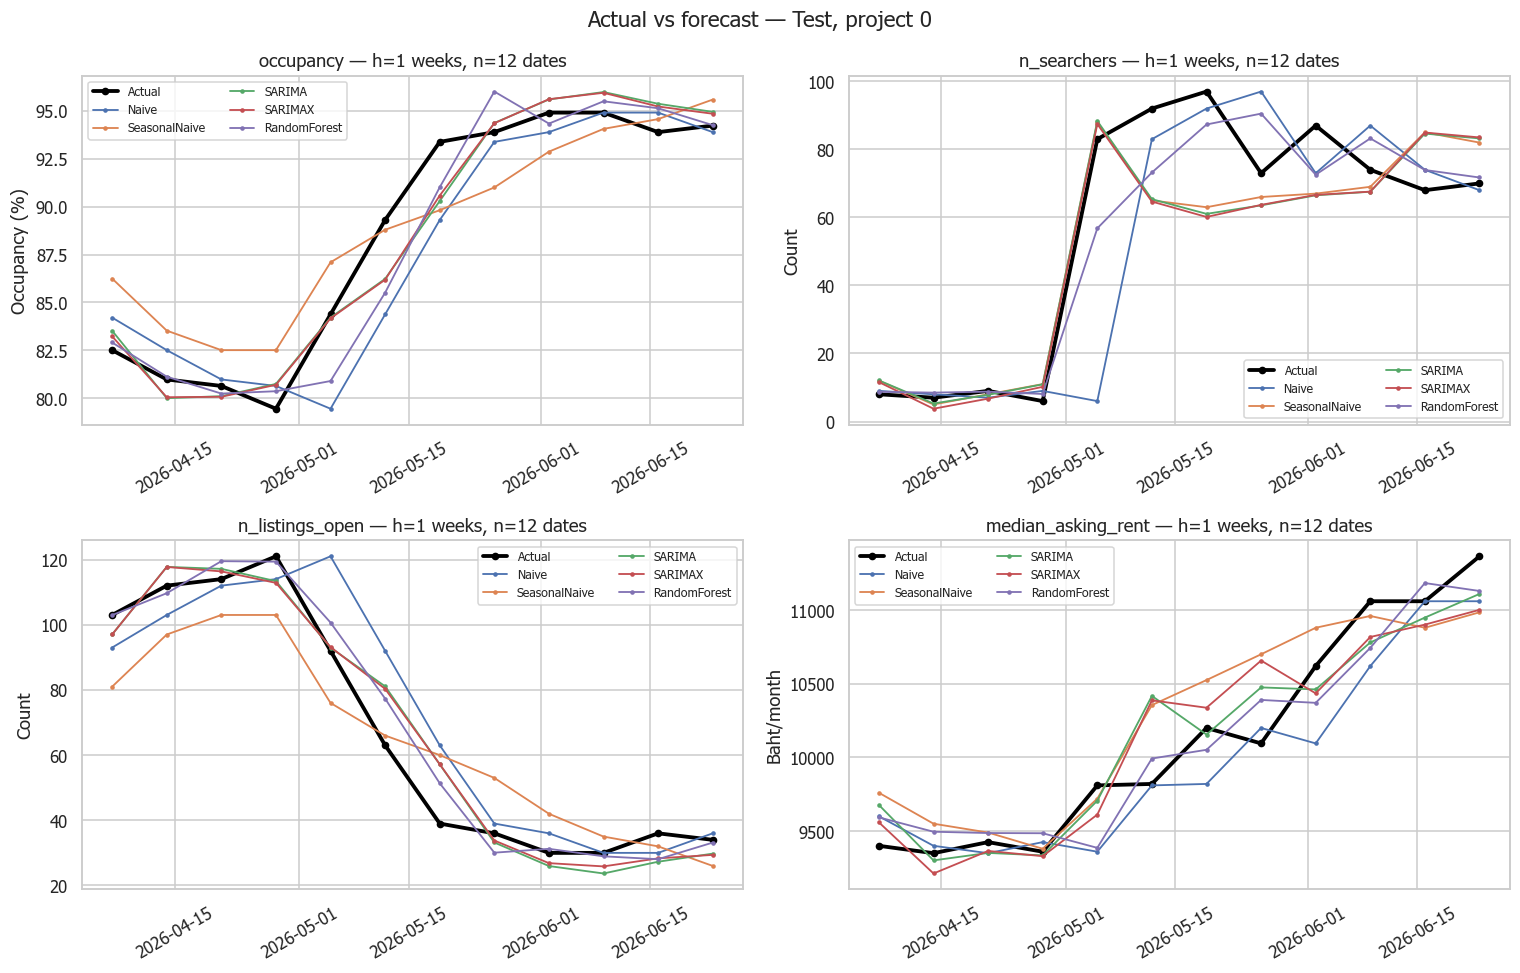

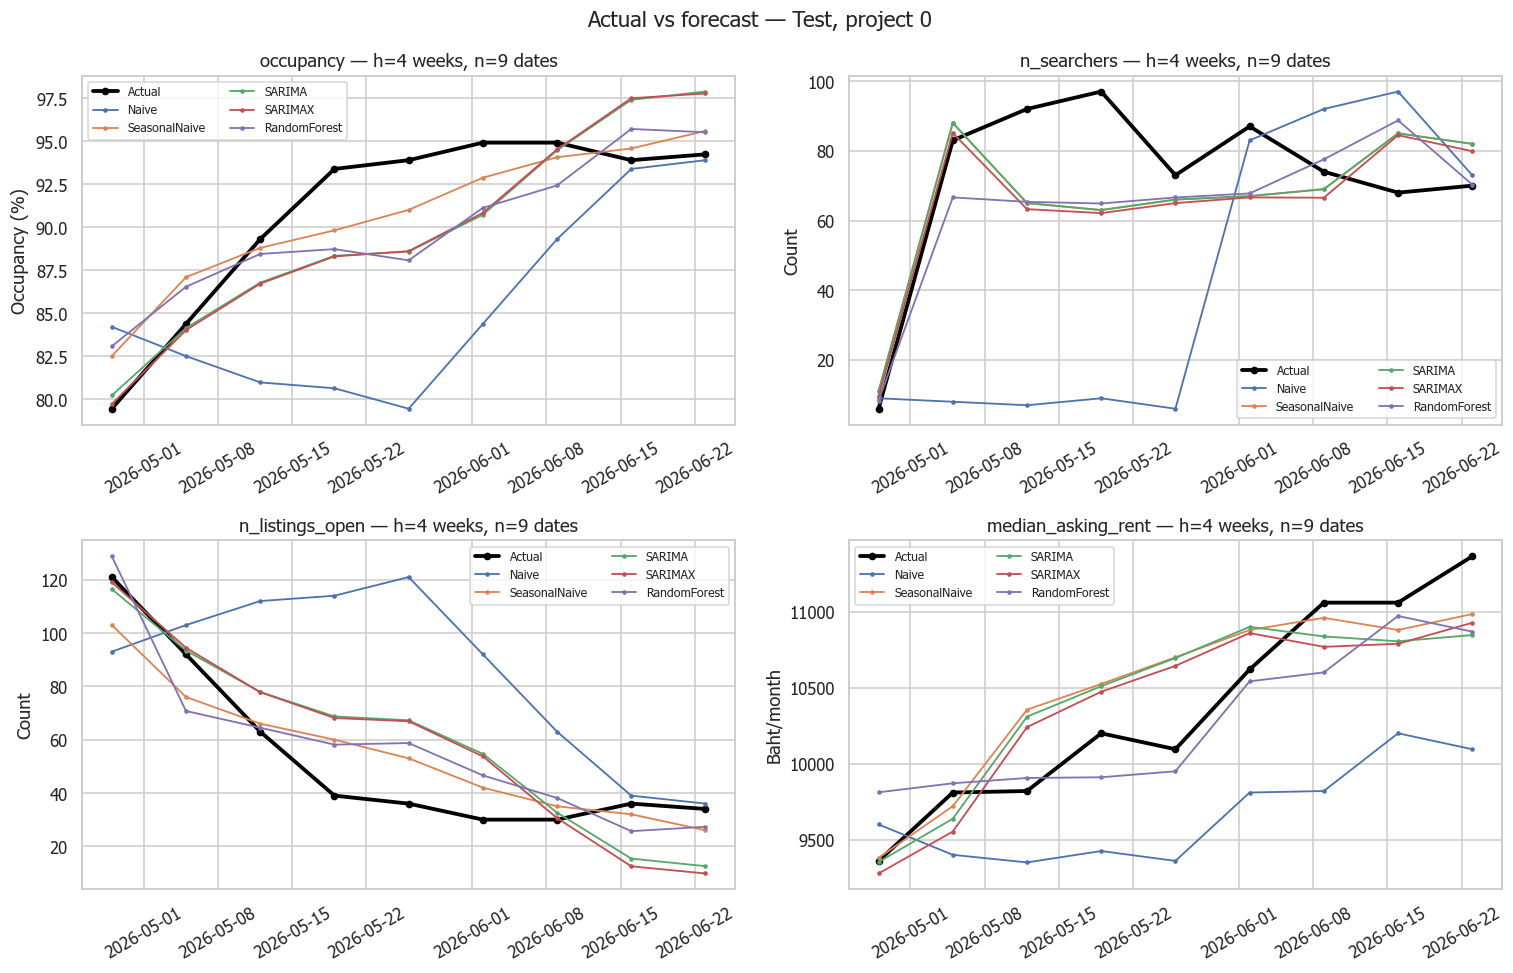

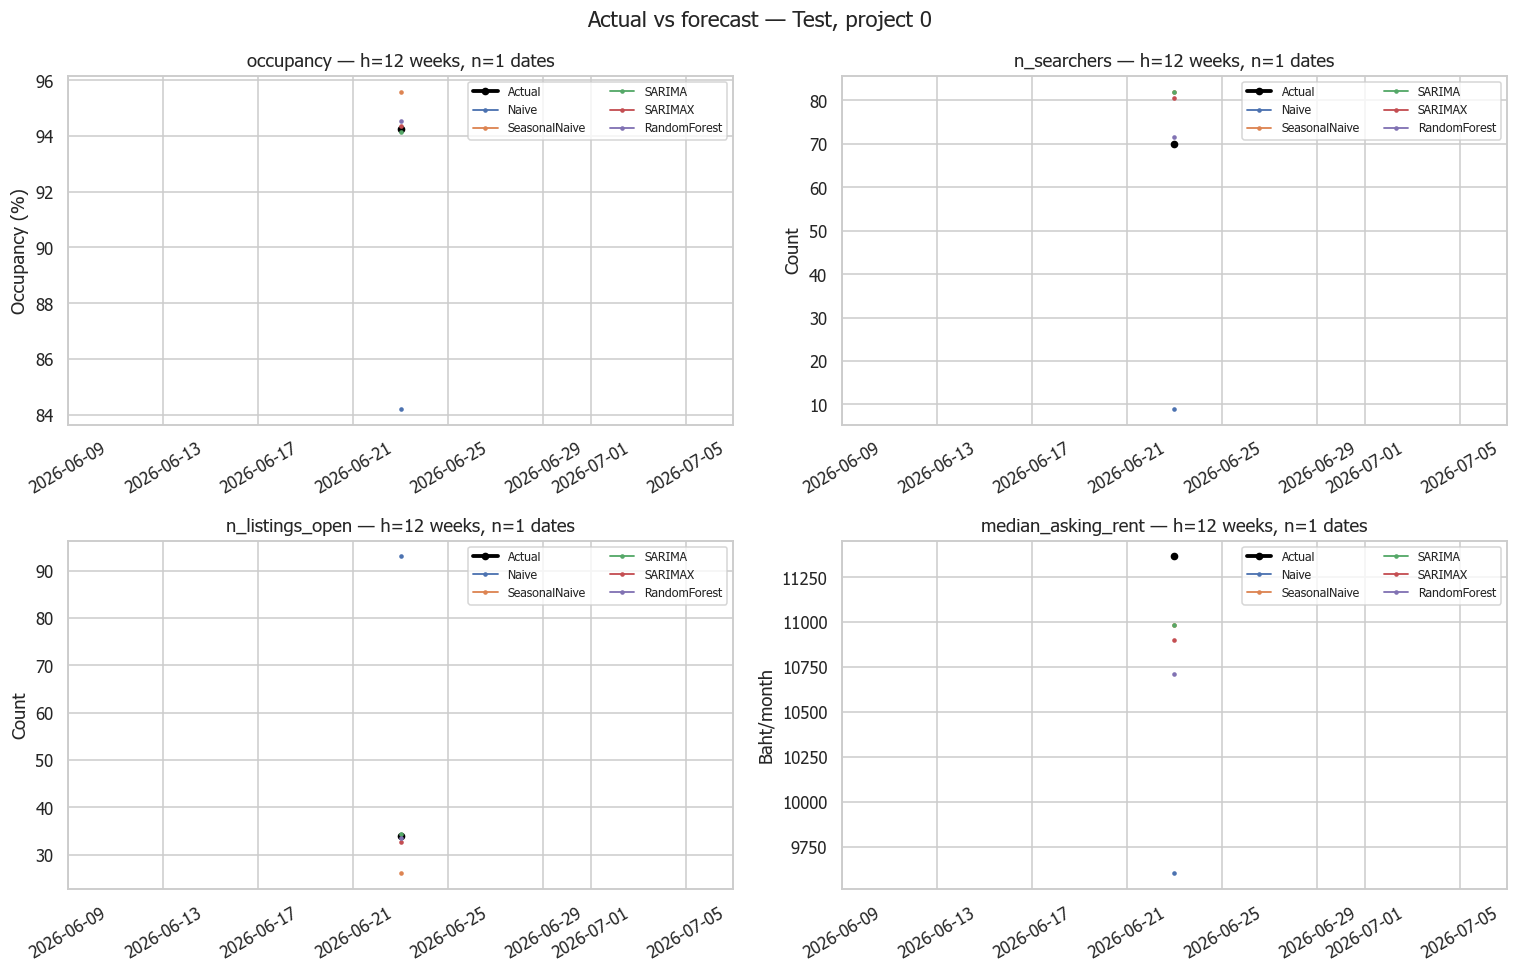

In [47]:
example_project_id = 0
for horizon in HORIZONS:
    fig, axes = plt.subplots(2, 2, figsize=(14, 9))
    for target, ax in zip(TARGETS, axes.flat):
        frame = test_common.loc[
            (test_common["project_id"] == example_project_id)
            & (test_common["horizon_weeks"] == horizon)
            & (test_common["target"] == target)
        ].sort_values("target_date")
        factor = 100 if target == "occupancy" else 1
        actual = frame.drop_duplicates("target_date")
        ax.plot(actual["target_date"], actual["actual"] * factor, color="black", linewidth=2.5, marker="o", markersize=4, label="Actual")
        for method in METHODS:
            forecast = frame.loc[(frame["method"] == method)]
            ax.plot(forecast["target_date"], forecast["prediction"] * factor, linewidth=1.2, marker=".", markersize=4, label=method)
        ax.set_title(f"{target} — h={horizon} weeks, n={len(actual)} dates")
        if len(actual) == 1:
            date = actual["target_date"].iloc[0]
            ax.set_xlim(date - pd.Timedelta(weeks=2), date + pd.Timedelta(weeks=2))
        ax.tick_params(axis="x", rotation=30)
        ax.set_ylabel("Occupancy (%)" if target == "occupancy" else "Baht/month" if target == "median_asking_rent" else "Count")
        ax.legend(fontsize=8, ncol=2)
    fig.suptitle(f"Actual vs forecast — Test, project {example_project_id}")
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / f"actual_vs_forecast_project_{example_project_id}_h{horizon}.png", dpi=150, bbox_inches="tight")
    plt.show()

## 11. ผลประวัติสั้นและข้อจำกัด

เปรียบเทียบ RF กับ Naïve ในกลุ่มที่มี input ย้อนหลัง 12 สัปดาห์ แต่ยังไม่ครบเกณฑ์ 104 จุด
กลุ่มนี้เป็นคนละชุดกับผลหลัก ห้ามนำคะแนนมาเรียงรวมกันกับ SARIMA/SARIMAX
โครงการที่ยังไม่มีประวัติ 12 สัปดาห์ไม่ถูกประเมินในรอบนี้ ดู project_readiness จากส่วนที่ 2 ประกอบ

In [48]:
short_history_scores = []
for split in ["Validation", "Test"]:
    short_predictions = experiment.run_or_load(split, ["Naive", "RandomForest"], cohort="short_history")
    if not short_predictions.empty:
        scores = score_predictions(short_predictions.dropna(subset=["prediction"]))
        short_history_scores.append(scores)
        scores.to_csv(EVALUATION_DIR / f"{split.lower()}_short_history_metrics.csv", index=False, encoding="utf-8-sig")
if short_history_scores:
    display(pd.concat(short_history_scores, ignore_index=True))

test_coverage = test_predictions.groupby(["target", "horizon_weeks", "method"])
test_coverage = test_coverage.agg(attempted=("prediction", "size"), successful=("prediction", "count"), clipped=("was_clipped", "sum"))
test_coverage = test_coverage.reset_index()
display(test_coverage)
test_coverage.to_csv(EVALUATION_DIR / "test_coverage.csv", index=False, encoding="utf-8-sig")

,target,horizon_weeks,method,split,n_predictions,mae_raw,rmse_raw,MAE,RMSE,unit
0,median_asking_rent,1,Naive,Validation,42,200.238095,313.615628,200.238095,313.615628,baht/month
1,median_asking_rent,1,RandomForest,Validation,42,250.353260,339.756509,250.353260,339.756509,baht/month
2,median_asking_rent,4,Naive,Validation,47,386.595745,489.944634,386.595745,489.944634,baht/month
3,median_asking_rent,4,RandomForest,Validation,47,527.239831,658.521562,527.239831,658.521562,baht/month
4,median_asking_rent,12,Naive,Validation,79,858.607595,1125.937022,858.607595,1125.937022,baht/month
5,median_asking_rent,12,RandomForest,Validation,79,416.036747,545.573550,416.036747,545.573550,baht/month
6,n_listings_open,1,Naive,Validation,42,3.428571,5.241774,3.428571,5.241774,count
7,n_listings_open,1,RandomForest,Validation,42,5.793714,11.573412,5.793714,11.573412,count
8,n_listings_open,4,Naive,Validation,47,6.787234,9.792529,6.787234,9.792529,count
9,n_listings_open,4,RandomForest,Validation,47,11.205996,13.078815,11.205996,13.078815,count


,target,horizon_weeks,method,attempted,successful,clipped
0,median_asking_rent,1,Naive,144,144,0
1,median_asking_rent,1,RandomForest,144,144,0
2,median_asking_rent,1,SARIMA,144,144,0
3,median_asking_rent,1,SARIMAX,144,144,0
4,median_asking_rent,1,SeasonalNaive,144,144,0
5,median_asking_rent,4,Naive,108,108,0
6,median_asking_rent,4,RandomForest,108,108,0
7,median_asking_rent,4,SARIMA,108,108,0
8,median_asking_rent,4,SARIMAX,108,108,0
9,median_asking_rent,4,SeasonalNaive,108,108,0


## 12. บันทึกโมเดลและสรุปผล

เก็บ selected_models.joblib และ model_metadata.json ใน models/market_occupancy/
fit coefficients ของโมเดลที่เลือกถึง Validation end ไม่ใช้ Test จูนหรือ fit coefficients
bundle นี้เป็นโมเดลสำหรับขั้นประเมิน ยังต้องทำส่วนเชื่อมต่อเว็บและอัปเดต state/exog ตามวันใช้งานจริง
baseline ที่ชนะเก็บประวัติและกฎพยากรณ์ ไม่เรียก baseline ว่า Random Forest/SARIMA

In [49]:
experiment.save_selected_models(winners)
main_summary = winners[["target", "horizon_weeks", "method", "MAE", "unit"]].rename(columns={"MAE": "Validation_MAE"})
main_summary = main_summary.merge(
    selected_test_scores[["target", "horizon_weeks", "method", "MAE", "RMSE", "n_predictions"]]
    .rename(columns={"MAE": "Test_MAE", "RMSE": "Test_RMSE"}),
    on=["target", "horizon_weeks", "method"], how="left",
)
display(main_summary)
main_summary.to_csv(EVALUATION_DIR / "selected_model_summary.csv", index=False, encoding="utf-8-sig")

,target,horizon_weeks,method,Validation_MAE,unit,Test_MAE,Test_RMSE,n_predictions
0,median_asking_rent,1,Naive,123.076923,baht/month,216.076389,380.906949,144
1,median_asking_rent,4,RandomForest,263.719347,baht/month,332.403531,474.443039,108
2,median_asking_rent,12,RandomForest,291.039751,baht/month,521.435561,638.491705,12
3,n_listings_open,1,SARIMA,3.987624,count,6.736979,9.609687,144
4,n_listings_open,4,SARIMA,8.535378,count,15.878161,22.043234,108
5,n_listings_open,12,SeasonalNaive,9.931034,count,7.500000,10.024969,12
6,n_searchers,1,SARIMA,4.356235,count,9.873403,14.368430,144
7,n_searchers,4,RandomForest,3.556556,count,11.674921,19.927858,108
8,n_searchers,12,RandomForest,4.800697,count,6.744237,8.610354,12
9,occupancy,1,SARIMA,0.491986,percentage points,0.872098,1.177539,144


In [50]:
lines = ["# ผลฝึกและประเมิน Market & Occupancy Forecasting", "",
         "ใช้ข้อมูลจำลอง ทดลองพารามิเตอร์รอบแรกคงที่ ไม่ใช่ผลจูนพารามิเตอร์ครบถ้วน",
         "เลือกจาก Validation MAE บนแถวร่วมกันครบ 5 วิธี แล้วล็อกก่อนประเมิน Test", "",
         "| Target | Horizon | วิธีที่เลือก | Validation MAE | Test MAE | หน่วย |",
         "|---|---:|---|---:|---:|---|"]
for row in main_summary.itertuples():
    lines.append(f"| {row.target} | {row.horizon_weeks} | {row.method} | {row.Validation_MAE:.4f} | {row.Test_MAE:.4f} | {row.unit} |")
lines += ["", f"แถวที่ไม่คืนผลพยากรณ์: {len(failures)} ตรวจ forecast_failures.csv และ fit_diagnostics.csv", "",
          "ผลหลักใช้ประวัติอย่างน้อย 104 จุดที่มี y และแถวที่ครบทุกวิธี กลุ่มประวัติสั้นแสดงแยกใน short_history_metrics",
          "ค่าที่ทราบหลัง fit cutoff แต่ก่อน origin ใช้ update state/inputs เท่านั้น ไม่ใช้ Test fit coefficients",
          "โมเดลเลือกต่างกันได้ตาม target/horizon และ baseline สามารถชนะได้ ไม่มีวิธีที่ดีที่สุดทุกกรณี",
          "ยังไม่เชื่อม Web Application และยังไม่สร้างเส้นทาง occupancy ทุกสัปดาห์ 1–12 สำหรับ What-if",
          "Test origin เริ่มหลังวันล็อก Validation (31 มีนาคม 2026); horizon 12 มี origin เดียว จึงต้องเพิ่มข้อมูลเพื่อประเมินความสม่ำเสมอ",
          "ไม่มีการอ้างผลจากข้อมูลจำลองเป็นประสิทธิภาพในธุรกิจจริง"]
training_summary = "\n".join(lines)
(EVALUATION_DIR / "training_summary.md").write_text(training_summary, encoding="utf-8")
display(Markdown(training_summary))
print("ผลการประเมิน:", EVALUATION_DIR)
print("โมเดล:", experiment.model_dir)

# ผลฝึกและประเมิน Market & Occupancy Forecasting

ใช้ข้อมูลจำลอง ทดลองพารามิเตอร์รอบแรกคงที่ ไม่ใช่ผลจูนพารามิเตอร์ครบถ้วน
เลือกจาก Validation MAE บนแถวร่วมกันครบ 5 วิธี แล้วล็อกก่อนประเมิน Test

| Target | Horizon | วิธีที่เลือก | Validation MAE | Test MAE | หน่วย |
|---|---:|---|---:|---:|---|
| median_asking_rent | 1 | Naive | 123.0769 | 216.0764 | baht/month |
| median_asking_rent | 4 | RandomForest | 263.7193 | 332.4035 | baht/month |
| median_asking_rent | 12 | RandomForest | 291.0398 | 521.4356 | baht/month |
| n_listings_open | 1 | SARIMA | 3.9876 | 6.7370 | count |
| n_listings_open | 4 | SARIMA | 8.5354 | 15.8782 | count |
| n_listings_open | 12 | SeasonalNaive | 9.9310 | 7.5000 | count |
| n_searchers | 1 | SARIMA | 4.3562 | 9.8734 | count |
| n_searchers | 4 | RandomForest | 3.5566 | 11.6749 | count |
| n_searchers | 12 | RandomForest | 4.8007 | 6.7442 | count |
| occupancy | 1 | SARIMA | 0.4920 | 0.8721 | percentage points |
| occupancy | 4 | SARIMAX | 0.9809 | 1.8175 | percentage points |
| occupancy | 12 | SARIMAX | 0.9907 | 2.1641 | percentage points |

แถวที่ไม่คืนผลพยากรณ์: 0 ตรวจ forecast_failures.csv และ fit_diagnostics.csv

ผลหลักใช้ประวัติอย่างน้อย 104 จุดที่มี y และแถวที่ครบทุกวิธี กลุ่มประวัติสั้นแสดงแยกใน short_history_metrics
ค่าที่ทราบหลัง fit cutoff แต่ก่อน origin ใช้ update state/inputs เท่านั้น ไม่ใช้ Test fit coefficients
โมเดลเลือกต่างกันได้ตาม target/horizon และ baseline สามารถชนะได้ ไม่มีวิธีที่ดีที่สุดทุกกรณี
ยังไม่เชื่อม Web Application และยังไม่สร้างเส้นทาง occupancy ทุกสัปดาห์ 1–12 สำหรับ What-if
Test origin เริ่มหลังวันล็อก Validation (31 มีนาคม 2026); horizon 12 มี origin เดียว จึงต้องเพิ่มข้อมูลเพื่อประเมินความสม่ำเสมอ
ไม่มีการอ้างผลจากข้อมูลจำลองเป็นประสิทธิภาพในธุรกิจจริง

ผลการประเมิน: D:\final project_\reports\market_occupancy\evaluation
โมเดล: D:\final project_\models\market_occupancy


# ส่วนที่ 4 จูนพารามิเตอร์โมเดล

จูน 3 โมเดลด้วย **TrainCV** จาก 4 forecast origins ที่อยู่ใน Train เดิมเท่านั้น
จากนั้นใช้ Validation เปรียบเทียบ 5 วิธีและเลือกโมเดลอีกครั้ง
เก็บโมเดลรอบจูนแยกจากโมเดลรอบแรก ไม่มีการเขียนทับผล Test เดิม

SARIMA/SARIMAX ทดลอง order 3 แบบ โดยคง d=0, D=1, s=52 และ P=Q=0 ไว้
Random Forest ทดลองจำนวนต้นไม้ ความลึก ขนาดใบ และสัดส่วน features 3 ชุด
มีค่าเริ่มต้นรวมอยู่ใน grid ด้วย จึงดูได้ว่าการจูนช่วย CV หรือไม่
นี่เป็นการค้นหาแบบจำกัด ไม่ใช่การค้นหาทุกพารามิเตอร์ที่เป็นไปได้

Test รอบแรกเคยถูกดูแล้ว จึงไม่ถือเป็นข้อมูลใหม่ที่ไม่เคยเห็นสำหรับการสรุปรอบจูน
ขั้นนี้ไม่ใช้คะแนน Test เลือกพารามิเตอร์และไม่ประเมิน Test ของโมเดลจูนซ้ำโดยอัตโนมัติ
หากต้องการ final holdout ที่เป็นอิสระ ควรใช้ข้อมูลอนาคตที่เพิ่มมาใหม่

โค้ดอ่านและแก้ grid ได้ใน `src/kaverentai/models/tune_market_occupancy.py`
ผลจูนอยู่ใน `reports/market_occupancy/tuning/` โมเดลใน `models/market_occupancy/tuned/`

## 1. ดูชุดพารามิเตอร์ที่จะทดลอง

order=(p,d,q): p คือจำนวน AR lags, d คือผลต่างปกติ, q คือจำนวน MA terms
seasonal_order=(P,D,Q,s) เป็นส่วนฤดูกาล ในรอบนี้คง seasonal differencing รายปีเหมือนรอบแรก
max_features ของ RF คือสัดส่วนตัวแปรที่ใช้พิจารณาแต่ละจุดแบ่งต้นไม้

In [51]:
from kaverentai.models.tune_market_occupancy import (
    CV_ORIGINS, GRIDS, TunedForecastExperiment, training_cv_cases,
    before_after_comparison,
)

grid_rows = []
for method, parameter_sets in GRIDS.items():
    for candidate_id, parameters in enumerate(parameter_sets):
        grid_rows.append({"method": method, "candidate_id": candidate_id, **parameters})
display(pd.DataFrame(grid_rows))
print("random_state=42 คงที่ทุกชุด และยังไม่ใช้ Validation/Test เลือก hyperparameters")

,method,candidate_id,order,seasonal_order,n_estimators,max_depth,min_samples_leaf,max_features
0,SARIMA,0,"[1, 0, 0]","[0, 1, 0, 52]",NaN,NaN,NaN,NaN
1,SARIMA,1,"[2, 0, 0]","[0, 1, 0, 52]",NaN,NaN,NaN,NaN
2,SARIMA,2,"[1, 0, 1]","[0, 1, 0, 52]",NaN,NaN,NaN,NaN
3,SARIMAX,0,"[1, 0, 0]","[0, 1, 0, 52]",NaN,NaN,NaN,NaN
4,SARIMAX,1,"[2, 0, 0]","[0, 1, 0, 52]",NaN,NaN,NaN,NaN
5,SARIMAX,2,"[1, 0, 1]","[0, 1, 0, 52]",NaN,NaN,NaN,NaN
6,RandomForest,0,NaN,NaN,100.0,8.0,4.0,1.0
7,RandomForest,1,NaN,NaN,200.0,12.0,2.0,0.7
8,RandomForest,2,NaN,NaN,200.0,NaN,8.0,1.0


random_state=42 คงที่ทุกชุด และยังไม่ใช้ Validation/Test เลือก hyperparameters


## 2. ตรวจวันจูนและคำตอบที่ใช้

คำตอบสุดท้ายของ CV คือ 25 พฤศจิกายน 2025 (2 กันยายน + 12 สัปดาห์)
พารามิเตอร์ที่เลือกจึงพร้อมใช้หลังวันนั้น Validation ต้องมี forecast_origin ไม่ก่อนวันดังกล่าว
และก่อน/หลังจูนจะเทียบเฉพาะแถวร่วมที่ผ่านเงื่อนไขนี้

แต่ละ origin เป็นหนึ่ง fold ใช้ประวัติทั้งหมดที่ทราบถึง origin นั้นในการ fit
แล้วประเมินที่ origin+h โดยทุก target date อยู่ใน Train ถึง 31 ธันวาคม 2025
4 origins เป็นจุดตัวแทนฤดูกาล ไม่ใช่การประเมินทุกสัปดาห์ของทั้งปี
ชุดจูนใช้เฉพาะโครงการที่มีประวัติอย่างน้อย 104 จุด ณ origin

In [52]:
tuner = TunedForecastExperiment(PROJECT_ROOT)
cv_design_rows = []
for (target, horizon), dataset in tuner.rf_data.items():
    cases = training_cv_cases(dataset)
    for origin, frame in cases.groupby("forecast_origin"):
        cv_design_rows.append({
            "target": target, "horizon_weeks": horizon,
            "fit_cutoff": origin, "forecast_origin": origin,
            "target_date": frame["target_date"].iloc[0],
            "projects": frame["project_id"].nunique(), "cases": len(frame),
        })
cv_design = pd.DataFrame(cv_design_rows)
display(cv_design)
assert (cv_design["target_date"] <= pd.Timestamp(TRAIN_END)).all()
assert (cv_design["fit_cutoff"] <= cv_design["forecast_origin"]).all()

,target,horizon_weeks,fit_cutoff,forecast_origin,target_date,projects,cases
0,occupancy,1,2024-12-31,2024-12-31,2025-01-07,8,8
1,occupancy,1,2025-04-01,2025-04-01,2025-04-08,8,8
2,occupancy,1,2025-07-01,2025-07-01,2025-07-08,8,8
3,occupancy,1,2025-09-02,2025-09-02,2025-09-09,8,8
4,occupancy,4,2024-12-31,2024-12-31,2025-01-28,8,8
5,occupancy,4,2025-04-01,2025-04-01,2025-04-29,8,8
6,occupancy,4,2025-07-01,2025-07-01,2025-07-29,8,8
7,occupancy,4,2025-09-02,2025-09-02,2025-09-30,8,8
8,occupancy,12,2024-12-31,2024-12-31,2025-03-25,8,8
9,occupancy,12,2025-04-01,2025-04-01,2025-06-24,8,8


## 3. รันการจูนภายใน Train

คะแนน CV ใช้ค่าเฉลี่ย MAE ของแต่ละ fold ให้แต่ละช่วงเวลามีน้ำหนักเท่ากัน
ถ้า candidate ไม่ลู่เข้าหรือคืนค่าพยากรณ์ไม่ครบ จะมี coverage ต่ำกว่า 1 และไม่ถูกเลือก
imputer/encoder/scaler fit ใหม่จากอดีตของแต่ละ fold ไม่ fit จากข้อมูลทั้งชุด
cache ตรวจทั้งโค้ด grid และข้อมูล ถ้าตรงกันจะโหลดผลเดิม

In [53]:
# จูนจาก TrainCV แล้วรับผลกลับมา 3 อย่าง
# cv_scores: คะแนนทุก candidate / chosen_parameters: ชุดที่ชนะ / parameter_map: ค่าที่โมเดลใช้
cv_scores, chosen_parameters, parameter_map = tuner.tune_on_train()
cv_scores_display = cv_scores.copy()
cv_scores_display["CV_MAE"] = cv_scores_display["cv_mae_raw"]
cv_scores_display["CV_RMSE"] = cv_scores_display["cv_rmse_raw"]

# occupancy เก็บเป็นสัดส่วน 0–1 จึงคูณ 100 เป็นจุดเปอร์เซ็นต์
is_occupancy = cv_scores_display["target"] == "occupancy"
for metric in ["CV_MAE", "CV_RMSE"]:
    cv_scores_display.loc[is_occupancy, metric] = cv_scores_display.loc[is_occupancy, metric] * 100
cv_columns = ["method", "target", "horizon_weeks", "candidate_id", "CV_MAE", "CV_RMSE", "coverage", "n_folds"]
display(cv_scores_display[cv_columns])

,method,target,horizon_weeks,candidate_id,CV_MAE,CV_RMSE,coverage,n_folds
0,RandomForest,median_asking_rent,1,0,322.222179,489.302777,1.0,4
1,RandomForest,median_asking_rent,1,1,319.207076,489.229090,1.0,4
2,RandomForest,median_asking_rent,1,2,322.919359,490.715361,1.0,4
3,RandomForest,median_asking_rent,4,0,431.867650,539.903325,1.0,4
4,RandomForest,median_asking_rent,4,1,416.802714,519.400304,1.0,4
...,...,...,...,...,...,...,...,...
103,SARIMAX,occupancy,4,1,0.996235,1.201121,1.0,4
104,SARIMAX,occupancy,4,2,0.954331,1.158228,1.0,4
105,SARIMAX,occupancy,12,0,0.988514,1.279893,1.0,4
106,SARIMAX,occupancy,12,1,1.014560,1.374174,1.0,4


## 4. ดูพารามิเตอร์ที่เลือก แยก target/horizon

หนึ่งโมเดลอาจใช้พารามิเตอร์ต่างกันสำหรับ occupancy กับราคา และสำหรับ h=1 กับ h=12
ค่า candidate_id=0 เป็นชุดเริ่มต้น จึงสามารถเลือกคงค่าเดิมได้เมื่อ CV ไม่ได้ดีขึ้นจากชุดอื่น

In [54]:
# แสดงชื่อชุดพารามิเตอร์และคะแนน CV ที่ใช้เลือก
chosen_rows = []
for _, row in chosen_parameters.iterrows():
    method = row["method"]
    candidate_id = int(row["candidate_id"])
    parameters = GRIDS[method][candidate_id]
    cv_mae = row["cv_mae_raw"]
    if row["target"] == "occupancy":
        cv_mae = cv_mae * 100
    chosen_rows.append({
        "method": method, "target": row["target"], "horizon_weeks": row["horizon_weeks"],
        "candidate_id": candidate_id,
        "parameters": json.dumps(parameters, ensure_ascii=False), "CV_MAE": cv_mae,
    })
chosen_table = pd.DataFrame(chosen_rows)
display(chosen_table.sort_values(["target", "horizon_weeks", "method"]))
print("บันทึกพารามิเตอร์แล้ว:", tuner.report_dir / "selected_hyperparameters.json")

,method,target,horizon_weeks,candidate_id,parameters,CV_MAE
27,RandomForest,median_asking_rent,1,1,"{""n_estimators"": 200, ""max_depth"": 12, ""min_sa...",319.207076
31,SARIMA,median_asking_rent,1,2,"{""order"": [1, 0, 1], ""seasonal_order"": [0, 1, ...",571.816122
32,SARIMAX,median_asking_rent,1,0,"{""order"": [1, 0, 0], ""seasonal_order"": [0, 1, ...",575.481765
28,RandomForest,median_asking_rent,4,1,"{""n_estimators"": 200, ""max_depth"": 12, ""min_sa...",416.802714
30,SARIMA,median_asking_rent,4,2,"{""order"": [1, 0, 1], ""seasonal_order"": [0, 1, ...",482.508589
29,SARIMAX,median_asking_rent,4,2,"{""order"": [1, 0, 1], ""seasonal_order"": [0, 1, ...",459.523509
33,RandomForest,median_asking_rent,12,2,"{""n_estimators"": 200, ""max_depth"": null, ""min_...",627.692553
34,SARIMA,median_asking_rent,12,0,"{""order"": [1, 0, 0], ""seasonal_order"": [0, 1, ...",819.227106
35,SARIMAX,median_asking_rent,12,0,"{""order"": [1, 0, 0], ""seasonal_order"": [0, 1, ...",833.437643
12,RandomForest,n_listings_open,1,1,"{""n_estimators"": 200, ""max_depth"": 12, ""min_sa...",6.494091


บันทึกพารามิเตอร์แล้ว: D:\final project_\reports\market_occupancy\tuning\selected_hyperparameters.json


## 5. ใช้พารามิเตอร์ CV ที่เลือกแล้วประเมิน Validation

สร้าง experiment ใหม่ที่ล็อก parameter_map จาก TrainCV
ใช้กฎ fit cutoff และการ update state/input แบบเดียวกับส่วนที่ 3
ห้ามปรับ grid ตามผล Test เดิม ไม่มีการประเมิน Test ของโมเดลจูนในส่วนนี้

In [55]:
# ส่ง parameter_map จาก TrainCV เข้า class รอบจูน แล้วประเมิน Validation
tuned_experiment = TunedForecastExperiment(PROJECT_ROOT, parameters=parameter_map)
print("พารามิเตอร์ CV พร้อมใช้ตั้งแต่:", tuned_experiment.parameter_selection_date().date())
tuned_validation = tuned_experiment.run_or_load("Validation", METHODS)
display(score_predictions(tuned_validation.dropna(subset=["prediction"])))

พารามิเตอร์ CV พร้อมใช้ตั้งแต่: 2025-11-25


,target,horizon_weeks,method,split,n_predictions,mae_raw,rmse_raw,MAE,RMSE,unit
0,median_asking_rent,1,Naive,Validation,156,123.076923,196.026228,123.076923,196.026228,baht/month
1,median_asking_rent,1,RandomForest,Validation,156,139.476728,205.522956,139.476728,205.522956,baht/month
2,median_asking_rent,1,SARIMA,Validation,156,201.987557,285.708907,201.987557,285.708907,baht/month
3,median_asking_rent,1,SARIMAX,Validation,156,215.528514,309.271974,215.528514,309.271974,baht/month
4,median_asking_rent,1,SeasonalNaive,Validation,156,387.884615,485.472279,387.884615,485.472279,baht/month
5,median_asking_rent,4,Naive,Validation,148,343.074324,442.060402,343.074324,442.060402,baht/month
6,median_asking_rent,4,RandomForest,Validation,148,262.078860,321.643480,262.078860,321.643480,baht/month
7,median_asking_rent,4,SARIMA,Validation,148,330.850106,437.933788,330.850106,437.933788,baht/month
8,median_asking_rent,4,SARIMAX,Validation,148,356.068634,490.517648,356.068634,490.517648,baht/month
9,median_asking_rent,4,SeasonalNaive,Validation,148,389.695946,487.044486,389.695946,487.044486,baht/month


## 6. เทียบก่อนและหลังจูนอย่างยุติธรรม

ใช้ project/origin/target/horizon ที่ทั้ง 5 วิธีในทั้งสองรอบคืนผลครบ
mae_improvement เป็น MAE ก่อนลบหลัง ค่าบวกคือดีขึ้น ค่าลบคือแย่ลง
ผล CV ดีขึ้นไม่ได้รับประกันว่า Validation จะดีขึ้นทุก target/horizon
สำหรับ h=12 ชุดร่วมเริ่มจาก origin 25 พฤศจิกายน 2025 จึงมีจำนวนแถวต่างจากตารางส่วนที่ 3 ที่ใช้ origin ก่อนหน้านั้นด้วย

In [56]:
# จับคู่ผลรอบแรก/หลังจูนให้ใช้กรณีเดียวกัน ก่อนเทียบ MAE
initial_validation = pd.read_csv(
    EVALUATION_DIR / "validation_all_predictions.csv",
    parse_dates=["forecast_origin", "target_date"],
)
tuning_common, tuning_comparison, tuned_validation_scores = before_after_comparison(
    initial_validation, tuned_validation,
)
display(tuning_comparison.loc[tuning_comparison["method"].isin(GRIDS), [
    "target", "horizon_weeks", "method", "MAE_before", "MAE_after", "mae_improvement", "n_predictions_after",
]].sort_values(["target", "horizon_weeks", "method"]))
assert (tuning_comparison["n_predictions_before"] == tuning_comparison["n_predictions_after"]).all()

,target,horizon_weeks,method,MAE_before,MAE_after,mae_improvement,n_predictions_after
1,median_asking_rent,1,RandomForest,135.927791,139.476728,-3.548938e+00,156
2,median_asking_rent,1,SARIMA,194.633411,201.987557,-7.354147e+00,156
3,median_asking_rent,1,SARIMAX,215.528514,215.528514,0.000000e+00,156
6,median_asking_rent,4,RandomForest,263.719347,262.078860,1.640487e+00,148
7,median_asking_rent,4,SARIMA,328.815482,330.850106,-2.034624e+00,148
8,median_asking_rent,4,SARIMAX,346.811788,356.068634,-9.256846e+00,148
11,median_asking_rent,12,RandomForest,257.881392,253.038276,4.843116e+00,68
12,median_asking_rent,12,SARIMA,349.720230,349.720230,0.000000e+00,68
13,median_asking_rent,12,SARIMAX,358.375223,358.375223,0.000000e+00,68
16,n_listings_open,1,RandomForest,4.400355,4.118816,2.815390e-01,156


## 7. เลือกผู้ชนะรอบจูนจาก Validation

เลือกจาก 3 โมเดลที่จูนด้วย TrainCV และสอง baseline เดิม บนชุดประเมินร่วมกัน
ค่าเดิมรอบแรกยังเก็บไว้ให้ดูการเปลี่ยนแปลง ไม่เขียนทับผลเก่า

In [57]:
tuned_winners = tuned_experiment.lock_selection(tuned_validation_scores)
tuned_winners = tuned_winners.sort_values(["target", "horizon_weeks"])
tuned_winners = tuned_winners.reset_index(drop=True)
display(tuned_winners[["target", "horizon_weeks", "method", "MAE", "RMSE", "unit", "n_predictions"]])

,target,horizon_weeks,method,MAE,RMSE,unit,n_predictions
0,median_asking_rent,1,Naive,123.076923,196.026228,baht/month,156
1,median_asking_rent,4,RandomForest,262.078860,321.643480,baht/month,148
2,median_asking_rent,12,RandomForest,253.038276,320.792731,baht/month,68
3,n_listings_open,1,SARIMA,3.987624,5.269094,count,156
4,n_listings_open,4,SARIMA,8.535378,10.800766,count,148
5,n_listings_open,12,SeasonalNaive,12.691176,16.622540,count,68
6,n_searchers,1,SARIMA,4.408411,6.052640,count,156
7,n_searchers,4,RandomForest,3.565712,4.685477,count,148
8,n_searchers,12,SARIMA,3.529412,4.687279,count,68
9,occupancy,1,SARIMA,0.491986,0.633899,percentage points,156


## 8. กราฟ MAE ของ occupancy ก่อนและหลังจูน

แสดง Validation MAE ของทั้ง 5 วิธี แยก horizon เป็นคนละกราฟย่อย
ใช้จุดเปอร์เซ็นต์ และทุกแท่งในกราฟย่อยเดียวกันใช้แถวประเมินชุดเดียวกัน

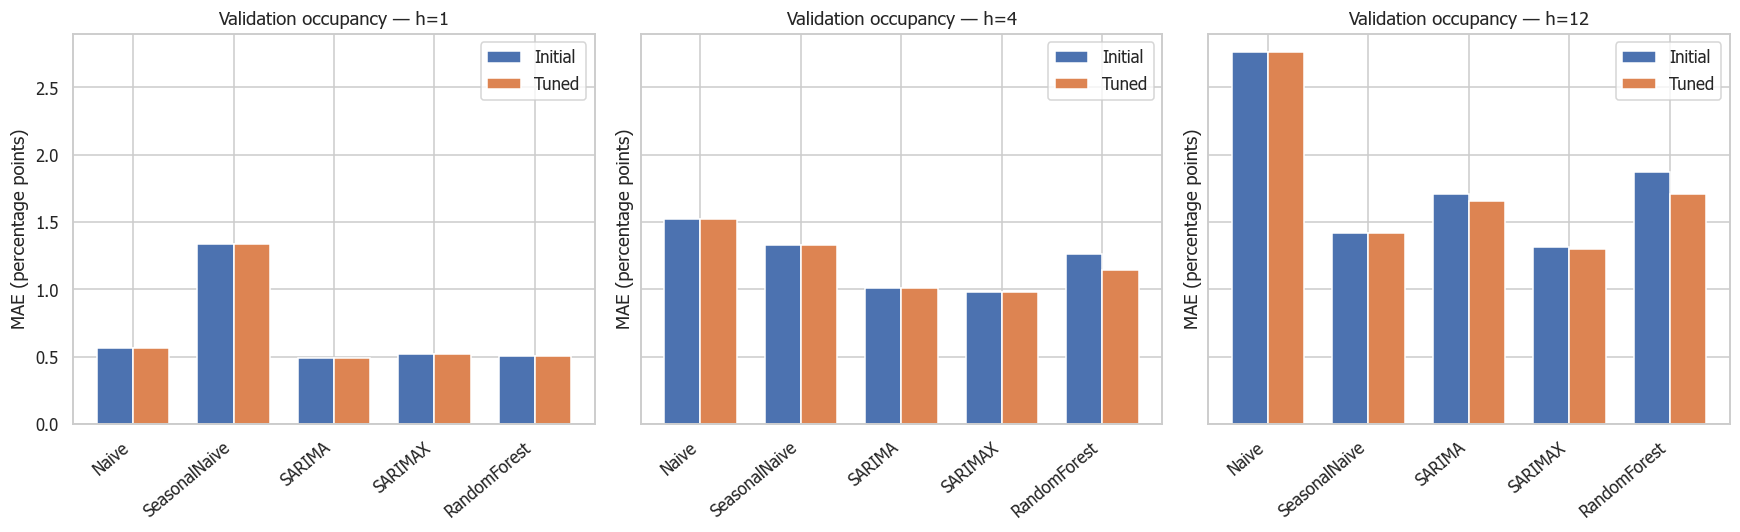

In [58]:
tuning_figure_dir = tuned_experiment.report_dir / "figures"
tuning_figure_dir.mkdir(parents=True, exist_ok=True)
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
for horizon, ax in zip(HORIZONS, axes):
    frame = tuning_comparison.loc[
        (tuning_comparison["target"] == "occupancy") & (tuning_comparison["horizon_weeks"] == horizon)
    ].set_index("method")
    frame = frame.reindex(METHODS)
    positions = np.arange(len(METHODS))
    ax.bar(positions - 0.18, frame["MAE_before"], width=0.36, label="Initial")
    ax.bar(positions + 0.18, frame["MAE_after"], width=0.36, label="Tuned")
    ax.set_xticks(positions, METHODS, rotation=40, ha="right")
    ax.set_title(f"Validation occupancy — h={horizon}")
    ax.set_ylabel("MAE (percentage points)")
    ax.legend()
fig.tight_layout()
fig.savefig(tuning_figure_dir / "occupancy_validation_mae_before_after.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. บันทึกโมเดลรอบจูนแยกจากรอบแรก

เก็บพารามิเตอร์ที่เลือกจาก CV และโมเดลที่เลือกจาก Validation
fit โมเดลสุดท้ายถึง Validation end โดยไม่ใช้ Test fit coefficients
ยังไม่มีคะแนน final holdout ใหม่ของโมเดลรอบจูน ไม่ใช้ Test เดิมยืนยันว่าจูนแล้วดีที่สุด

In [59]:
tuned_experiment.save_selected_models(tuned_winners)
print("โมเดลรอบจูน:", tuned_experiment.model_dir / "selected_models.joblib")
print("รายละเอียด:", tuned_experiment.model_dir / "model_metadata.json")

โมเดลรอบจูน: D:\final project_\models\market_occupancy\tuned\selected_models.joblib
รายละเอียด: D:\final project_\models\market_occupancy\tuned\model_metadata.json


## 10. บันทึกผลและสรุปจากตัวเลขจริง

CV metrics, การเลือกพารามิเตอร์ และ before/after สามารถนำไปใช้ในรายงานได้
ขอบเขตการค้นหารอบนี้มี 3 candidates ต่อ family, 4 origins และเน้นโครงการที่มีประวัติอย่างน้อยสองปี
อย่าอธิบายว่าเป็น exhaustive search หรือประสิทธิภาพที่ยืนยันกับธุรกิจจริง

In [60]:
TUNING_DIR = tuned_experiment.report_dir
cv_design.to_csv(TUNING_DIR / "cv_design.csv", index=False, encoding="utf-8-sig")
chosen_table.to_csv(TUNING_DIR / "selected_parameter_table.csv", index=False, encoding="utf-8-sig")
tuning_comparison.to_csv(TUNING_DIR / "validation_before_after.csv", index=False, encoding="utf-8-sig")
tuned_validation_scores.to_csv(TUNING_DIR / "tuned_validation_metrics.csv", index=False, encoding="utf-8-sig")
tuned_winners.to_csv(TUNING_DIR / "tuned_winners.csv", index=False, encoding="utf-8-sig")

In [61]:
model_comparison = tuning_comparison.loc[tuning_comparison["method"].isin(GRIDS)]
improved = int((model_comparison["mae_improvement"] > 1e-10).sum())
worse = int((model_comparison["mae_improvement"] < -1e-10).sum())
unchanged = len(model_comparison) - improved - worse
summary_lines = [
    "# ผลจูน Market & Occupancy Forecasting", "",
    "ใช้ข้อมูลจำลอง จูนพารามิเตอร์จาก TrainCV เท่านั้น แล้วเลือกโมเดลจาก Validation", "",
    f"- 3 โมเดล × 3 candidates × 4 targets × 3 horizons = {len(cv_scores)} ชุดคะแนน CV",
    f"- CV origins: {CV_ORIGINS}; ทุก target_date ไม่เกิน {TRAIN_END}",
    "- SARIMA/SARIMAX จูน p และ q โดยคง d=0, seasonal_order=(0,1,0,52)",
    "- RF จูน n_estimators, max_depth, min_samples_leaf และ max_features",
    f"- Validation MAE ของ 36 งานโมเดล: ดีขึ้น {improved}, แย่ลง {worse}, เท่าเดิม {unchanged}",
    "- ไม่ใช้ Test เลือกพารามิเตอร์ และไม่ประเมิน Test ของโมเดลจูนซ้ำในรอบนี้",
    "- Test รอบแรกเคยถูกดูแล้ว จึงต้องมีข้อมูลอนาคตใหม่สำหรับ final holdout ที่เป็นอิสระ",
    f"- Validation origin ต้องไม่ก่อน {tuned_experiment.parameter_selection_date():%Y-%m-%d} เมื่อคำตอบ CV สุดท้ายทราบแล้ว", "",
    "| Target | Horizon | วิธีที่เลือกหลังจูน | Validation MAE | หน่วย |",
    "|---|---:|---|---:|---|",
]
for row in tuned_winners.itertuples():
    summary_lines.append(f"| {row.target} | {row.horizon_weeks} | {row.method} | {row.MAE:.4f} | {row.unit} |")
summary_lines += ["", "รอบนี้เป็น small-grid search บน 4 origins ไม่ใช่การค้นหาพารามิเตอร์ครบทุกแบบ",
                  "ผลก่อน/หลังใช้แถวเดียวกันทั้ง 5 วิธีในทั้งสองรอบ และ candidate ที่คืนผลไม่ครบไม่ถูกเลือก",
                  "โมเดลรอบแรกยังอยู่ที่ models/market_occupancy ส่วนรอบจูนอยู่ใน models/market_occupancy/tuned"]
tuning_summary = "\n".join(summary_lines)
(TUNING_DIR / "tuning_summary.md").write_text(tuning_summary, encoding="utf-8")
display(Markdown(tuning_summary))

# ผลจูน Market & Occupancy Forecasting

ใช้ข้อมูลจำลอง จูนพารามิเตอร์จาก TrainCV เท่านั้น แล้วเลือกโมเดลจาก Validation

- 3 โมเดล × 3 candidates × 4 targets × 3 horizons = 108 ชุดคะแนน CV
- CV origins: ['2024-12-31', '2025-04-01', '2025-07-01', '2025-09-02']; ทุก target_date ไม่เกิน 2025-12-31
- SARIMA/SARIMAX จูน p และ q โดยคง d=0, seasonal_order=(0,1,0,52)
- RF จูน n_estimators, max_depth, min_samples_leaf และ max_features
- Validation MAE ของ 36 งานโมเดล: ดีขึ้น 13, แย่ลง 10, เท่าเดิม 13
- ไม่ใช้ Test เลือกพารามิเตอร์ และไม่ประเมิน Test ของโมเดลจูนซ้ำในรอบนี้
- Test รอบแรกเคยถูกดูแล้ว จึงต้องมีข้อมูลอนาคตใหม่สำหรับ final holdout ที่เป็นอิสระ
- Validation origin ต้องไม่ก่อน 2025-11-25 เมื่อคำตอบ CV สุดท้ายทราบแล้ว

| Target | Horizon | วิธีที่เลือกหลังจูน | Validation MAE | หน่วย |
|---|---:|---|---:|---|
| median_asking_rent | 1 | Naive | 123.0769 | baht/month |
| median_asking_rent | 4 | RandomForest | 262.0789 | baht/month |
| median_asking_rent | 12 | RandomForest | 253.0383 | baht/month |
| n_listings_open | 1 | SARIMA | 3.9876 | count |
| n_listings_open | 4 | SARIMA | 8.5354 | count |
| n_listings_open | 12 | SeasonalNaive | 12.6912 | count |
| n_searchers | 1 | SARIMA | 4.4084 | count |
| n_searchers | 4 | RandomForest | 3.5657 | count |
| n_searchers | 12 | SARIMA | 3.5294 | count |
| occupancy | 1 | SARIMA | 0.4920 | percentage points |
| occupancy | 4 | SARIMAX | 0.9809 | percentage points |
| occupancy | 12 | SARIMAX | 1.3009 | percentage points |

รอบนี้เป็น small-grid search บน 4 origins ไม่ใช่การค้นหาพารามิเตอร์ครบทุกแบบ
ผลก่อน/หลังใช้แถวเดียวกันทั้ง 5 วิธีในทั้งสองรอบ และ candidate ที่คืนผลไม่ครบไม่ถูกเลือก
โมเดลรอบแรกยังอยู่ที่ models/market_occupancy ส่วนรอบจูนอยู่ใน models/market_occupancy/tuned